# PI-CycleEV: Physics-Informed Cycle-Consistent GAN for Unpaired Cross-Season Multivariate Time-Series Synthesis in Electric Vehicles

**Course:** Machine Learning (Fall 2026) | **Instructor:** Ms. Poma Panezai | **Department:** Computer Science, BUITEMS

## 00 — Title, team, objective, links, run instructions

### Team members
| Name | Student ID |
|---|---|
| Muhammad Muntazir | 66305 |
| Taskeen Fatima | 66757 |
| Arooj Fatima | 66703 |

### Objective
This notebook reproduces the **TS-p2pGAN** baseline (Jeng, 2025, *Sensors*), then extends it into **PI-CycleEV**: an unpaired 1D CycleGAN that translates electric-vehicle driving time series between summer and winter domains without matched trip pairs, with physics-informed losses (SOC-current consistency, velocity-acceleration consistency, and a window-level plausibility penalty). It compares the baseline, a standard CycleGAN and PI-CycleEV on fidelity, distribution, physical consistency and downstream SOC estimation, and runs an ablation of the physics terms.

### Links
- **Base paper:** S.-L. Jeng, "Generative Adversarial Network for Synthesizing Multivariate Time-Series Data in Electric Vehicle Driving Scenarios," *Sensors*, 25(3), Art. 749, 2025. DOI: 10.3390/s25030749
- **Dataset:** Battery and Heating Data for Real Driving Cycles, IEEE DataPort: https://ieee-dataport.org/open-access/battery-and-heating-data-real-driving-cycles (download the **measurement data** zip, not the simulation data)
- **Code repository:** _add the GitHub link here_

### How to run this notebook
1. **Dataset:** put the unzipped trip CSVs (TripA01.csv ... TripB38.csv) in `PI_CycleEV_Project/dataset/` on Google Drive, or put the downloaded zip anywhere inside `PI_CycleEV_Project/` and Section 01 will unpack it. The only path to edit is `PROJECT_ROOT` in cell 01.1.
2. **Mode:** set `TEST_MODE` in cell 01.3. True runs the whole pipeline on a small subset with 2 training epochs (a quick check that everything works). False is the FULL TRAIN configuration used for the paper's results.
3. **Full mode retraining:** by default, full mode reuses saved model weights if they exist in `models/`. Set `RETRAIN_IN_FULL_MODE = True` in 01.3 to retrain everything from scratch (hours on a GPU).
4. Use a **GPU runtime** (Runtime > Change runtime type > T4 GPU), then **Runtime > Run all**.
5. Everything the notebook writes goes to `results/` (metrics, figures) and `models/` (checkpoints).

### Training notes (read before comparing with the base paper)
- **Epochs:** baseline TS-p2pGAN 50 epochs (the base paper used 800); every CycleGAN run (E2, E3 and the three ablations) 100 epochs. The baseline is paired and the CycleGANs are unpaired, so the two budgets are not directly comparable.
- **Resumed runs:** the E3 run (`picycleev`) was continued from its epoch-70 checkpoint and the `abl_no_range` run from its epoch-20 checkpoint after Colab sessions ended. Only the generators are checkpointed, so the discriminators and optimisers were re-initialised at that point (cell 08.1, `resume=True`).
- **Single runs:** each model was trained once (seed 42), so no confidence intervals are reported.


In [1]:
# ==========================================
# 01.1 - PATHS, GOOGLE DRIVE AND DATASET CHECK
# ==========================================
import os, sys, glob, zipfile, time
NOTEBOOK_START = time.time()

IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_ROOT = '/content/drive/MyDrive/PI_CycleEV_Project'    # <-- the ONLY line to edit if your project folder is elsewhere
else:
    PROJECT_ROOT = os.path.abspath('PI_CycleEV_Project')           # running outside Colab: a folder next to this notebook

for sub in ['dataset', 'results/figures', 'results/generated_samples', 'models']:
    os.makedirs(f'{PROJECT_ROOT}/{sub}', exist_ok=True)

def find_trips():
    found = {}
    for p in sorted(glob.glob(f'{PROJECT_ROOT}/**/Trip*.csv', recursive=True)):
        found.setdefault(os.path.basename(p), p)                  # one file per trip name, first location wins
    return [found[k] for k in sorted(found)]

all_trips = find_trips()
if not all_trips:                                                  # no CSVs yet: unpack a downloaded zip if there is one
    for z in glob.glob(f'{PROJECT_ROOT}/**/*.zip', recursive=True):
        print("Extracting", z)
        with zipfile.ZipFile(z) as zf:
            zf.extractall(f'{PROJECT_ROOT}/dataset')
    all_trips = find_trips()

summer = [p for p in all_trips if os.path.basename(p).startswith('TripA')]
winter = [p for p in all_trips if os.path.basename(p).startswith('TripB')]
DATA_DIR = os.path.dirname(all_trips[0]) if all_trips else f'{PROJECT_ROOT}/dataset'
print("Project root:", PROJECT_ROOT)
print(f"Trips found in {DATA_DIR}: {len(summer)} summer (TripA) and {len(winter)} winter (TripB)")
assert len(summer) == 32 and len(winter) == 38, (
    "Dataset not found or incomplete (expected 32 summer + 38 winter trips).\n"
    "Download the 'measurement data' zip from IEEE DataPort "
    "(https://ieee-dataport.org/open-access/battery-and-heating-data-real-driving-cycles), "
    f"then unzip it into {PROJECT_ROOT}/dataset/ or leave the zip anywhere inside {PROJECT_ROOT}/.")

Mounted at /content/drive
Project root: /content/drive/MyDrive/PI_CycleEV_Project
Trips found in /content/drive/MyDrive/PI_CycleEV_Project/dataset: 32 summer (TripA) and 38 winter (TripB)


In [2]:
# ==========================================
# 01.2 - DEPENDENCIES (only what Colab does not already provide)
# ==========================================
try:
    import tslearn
except ImportError:
    import subprocess
    subprocess.run([sys.executable, '-m', 'pip', 'install', 'tslearn', '-q'], check=False)
    import tslearn
print("Dependencies ready.")

Dependencies ready.


In [3]:
# ==========================================
# 01.3 - SEEDS, GPU, TEST MODE / FULL TRAIN CONFIGURATION, LIBRARY VERSIONS
# ==========================================
import random, platform
import numpy as np, pandas as pd, tensorflow as tf, sklearn, scipy

# ---------------- the switches you may change ----------------
TEST_MODE = False              # True = quick pipeline check on a small subset;  False = FULL TRAIN (the paper's results)
RETRAIN_IN_FULL_MODE = False  # False: in full mode reuse saved model weights if they exist;  True: retrain everything (hours)
RUN_ABLATIONS = True          # Section 11 trains 3 extra models; set False to skip them if time is short
# --------------------------------------------------------------
RETRAIN = TEST_MODE or RETRAIN_IN_FULL_MODE

SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

gpus = tf.config.list_physical_devices('GPU')
GPU_NAME = gpus[0].name if gpus else 'none (CPU)'
print("GPU devices:", gpus)
if not gpus:
    print("WARNING: no GPU. Full training needs one: Runtime > Change runtime type > T4 GPU.")

WINDOW_SIZE = 256
if TEST_MODE:
    NUM_TRIPS_PER_DOMAIN = 4     # trips per season used for training in test mode (val/test: 2 each)
    BATCH_SIZE, STRIDE = 16, 32
    P2P_EPOCHS, CYCLE_EPOCHS = 2, 2
    print("Running in TEST MODE: small subset, 2 epochs. Numbers from this mode are NOT results.")
else:
    NUM_TRIPS_PER_DOMAIN = None  # all trips
    BATCH_SIZE, STRIDE = 256, 4
    P2P_EPOCHS = 50              # baseline epochs: set after timing one epoch (the paper used 800 on an RTX 4090)
    CYCLE_EPOCHS = 100           # also used for E2, E3 and every ablation run, so they stay comparable
    print("Running in FULL TRAIN mode.")
tag = "test" if TEST_MODE else "full"      # suffix of every file this mode writes, so the two modes never overwrite each other

print(f"\nPython {platform.python_version()} | TensorFlow {tf.__version__} | NumPy {np.__version__} | "
      f"pandas {pd.__version__} | scikit-learn {sklearn.__version__} | SciPy {scipy.__version__} | tslearn {tslearn.__version__}")
print(f"Config: mode={tag}, seed={SEED}, window={WINDOW_SIZE}, stride={STRIDE}, batch={BATCH_SIZE}, "
      f"baseline epochs={P2P_EPOCHS}, cyclegan epochs={CYCLE_EPOCHS}, retrain={RETRAIN}")

GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Running in FULL TRAIN mode.

Python 3.13.16 | TensorFlow 2.21.0 | NumPy 2.4.6 | pandas 2.2.3 | scikit-learn 1.6.1 | SciPy 1.16.3 | tslearn 0.10.0
Config: mode=full, seed=42, window=256, stride=4, batch=256, baseline epochs=50, cyclegan epochs=100, retrain=False


In [4]:
# ==========================================
# 02.1 - LOAD ALL TRIPS (once; later sections reuse them)
# ==========================================
import re
import matplotlib.pyplot as plt

def load_trip(path):
    """Load one trip CSV (Latin-1; ';' or ',' separator) and clean the column names."""
    for sep in [';', ',']:
        df = pd.read_csv(path, encoding='latin-1', sep=sep)
        if df.shape[1] > 1:
            break
    df.columns = [re.sub(r'\]+$', ']', c.strip()) for c in df.columns]      # e.g. 'Velocity [km/h]]]' -> 'Velocity [km/h]'
    return df

raw = {os.path.basename(p).replace('.csv', ''): load_trip(p) for p in all_trips}
print(f"Loaded {len(raw)} trips: {sum(n.startswith('TripA') for n in raw)} summer, {sum(n.startswith('TripB') for n in raw)} winter")

sample_name = sorted(raw)[0]
sample = raw[sample_name]
print(f"\nSample file: {sample_name} | shape {sample.shape}")
print("Columns:")
for i, c in enumerate(sample.columns):
    print(f"  {i:2d}. {c}")
display(sample.head())

Loaded 70 trips: 32 summer, 38 winter

Sample file: TripA01 | shape (10090, 28)
Columns:
   0. Time [s]
   1. Velocity [km/h]
   2. Elevation [m]
   3. Throttle [%]
   4. Motor Torque [Nm]
   5. Longitudinal Acceleration [m/s^2]
   6. Regenerative Braking Signal
   7. Battery Voltage [V]
   8. Battery Current [A]
   9. Battery Temperature [°C]
  10. max. Battery Temperature [°C]
  11. SoC [%]
  12. displayed SoC [%]
  13. min. SoC [%]
  14. max. SoC [%)
  15. Heating Power CAN [kW]
  16. Heating Power LIN [W]
  17. Requested Heating Power [W]
  18. AirCon Power [kW]
  19. Heater Signal
  20. Heater Voltage [V]
  21. Heater Current [A]
  22. Ambient Temperature [°C]
  23. Coolant Temperature Heatercore [°C]
  24. Requested Coolant Temperature [°C]
  25. Coolant Temperature Inlet [°C]
  26. Heat Exchanger Temperature [°C]
  27. Cabin Temperature Sensor [°C]


,Time [s],Velocity [km/h],Elevation [m],Throttle [%],Motor Torque [Nm],Longitudinal Acceleration [m/s^2],Regenerative Braking Signal,Battery Voltage [V],Battery Current [A],Battery Temperature [°C],...,AirCon Power [kW],Heater Signal,Heater Voltage [V],Heater Current [A],Ambient Temperature [°C],Coolant Temperature Heatercore [°C],Requested Coolant Temperature [°C],Coolant Temperature Inlet [°C],Heat Exchanger Temperature [°C],Cabin Temperature Sensor [°C]
0,0.0,0.0,574.0,0.0,0.0,-0.03,0.0,391.4,-2.20,21.0,...,0.4,1,0,0,25.5,0,0,0,30.5,24.5
1,0.1,0.0,574.0,0.0,0.0,0.00,0.0,391.4,-2.21,21.0,...,0.4,1,0,0,25.5,0,0,0,30.5,24.5
2,0.2,0.0,574.0,0.0,0.0,-0.01,0.0,391.4,-2.26,21.0,...,0.4,1,0,0,25.5,0,0,0,30.5,24.5
3,0.3,0.0,574.0,0.0,0.0,-0.03,0.0,391.4,-2.30,21.0,...,0.4,1,0,0,25.5,0,0,0,30.5,24.5
4,0.4,0.0,574.0,0.0,0.0,-0.03,0.0,391.4,-2.30,21.0,...,0.4,1,0,0,25.5,0,0,0,30.5,24.5


In [5]:
# ==========================================
# 02.2 - FEATURE MAPPING (single source of truth) AND CHECK OF EVERY TRIP
# ==========================================
# Documented mapping from raw dataset columns to the 14 signals of the base paper (10 conditioning inputs + 4 targets).
INPUT_COLS = {
    'current':   'Battery Current [A]',
    'throttle':  'Throttle [%]',
    'velocity':  'Velocity [km/h]',
    'elevation': 'Elevation [m]',            # converted to elevation CHANGE in Section 03
    'heat_req':  'Requested Heating Power [W]',
    'aircon':    'AirCon Power [kW]',
    'heater_v':  'Heater Voltage [V]',       # absent in 20 summer trips: filled with 0 in Section 03 (heater not logged)
    'heater_i':  'Heater Current [A]',       # absent in 20 summer trips: filled with 0 in Section 03
    'batt_temp': 'Battery Temperature [°C]',
    'amb_temp':  'Ambient Temperature [°C]',
}
OUTPUT_COLS = {
    'soc':     'SoC [%]',
    'voltage': 'Battery Voltage [V]',
    'torque':  'Motor Torque [Nm]',
    'accel':   'Longitudinal Acceleration [m/s^2]',
}
ALL_COLS = {**INPUT_COLS, **OUTPUT_COLS}
BATTERY_CAPACITY_AH = 60.0                   # nominal BMW i3 (60 Ah)

rows = []
for name, df in raw.items():
    present = [c for c in ALL_COLS.values() if c in df.columns]
    rows.append({
        'trip': name, 'season': 'summer' if name.startswith('TripA') else 'winter',
        'rows': len(df), 'duration_min': round(df['Time [s]'].iloc[-1] / 60, 1),
        'dt_s': round(df['Time [s]'].diff().median(), 3),
        'nan_values': int(df[present].isna().sum().sum()),
        'missing_cols': [c for c in ALL_COLS.values() if c not in df.columns],
    })
summary = pd.DataFrame(rows)
print("Trips with missing columns:", int((summary['missing_cols'].str.len() > 0).sum()), "(handled in Section 03)")
print("Trips with NaN values:     ", int((summary['nan_values'] > 0).sum()), "(trailing SoC values, trimmed in Section 03)")
print("Sampling intervals found:  ", summary['dt_s'].unique())
print("\nPer-season trip length (minutes):")
print(summary.groupby('season')['duration_min'].describe().round(1))
display(summary.head(10))

# Current sign convention (required by the brief): integrate current and compare with the SoC change.
df = raw[sorted(raw)[0]]
dt = df['Time [s]'].diff().fillna(0.1)
charge_Ah = (df['Battery Current [A]'] * dt).sum() / 3600
actual_dsoc = df['SoC [%]'].dropna().iloc[-1] - df['SoC [%]'].dropna().iloc[0]
print(f"\nSign check on {sorted(raw)[0]}: integrated current {charge_Ah:.3f} Ah | actual SoC change {actual_dsoc:.2f} % | "
      f"implied if NEGATIVE current = discharge: {charge_Ah / BATTERY_CAPACITY_AH * 100:.2f} %")

Trips with missing columns: 20 (handled in Section 03)
Trips with NaN values:      27 (trailing SoC values, trimmed in Section 03)
Sampling intervals found:   [0.1]

Per-season trip length (minutes):
        count  mean   std  min   25%   50%   75%   max
season                                                
summer   32.0  24.4  10.7  6.9  16.3  23.6  30.6  52.7
winter   38.0  27.5  17.6  5.9  17.0  22.8  29.6  93.5


,trip,season,rows,duration_min,dt_s,nan_values,missing_cols
0,TripA01,summer,10090,16.8,0.1,0,[]
1,TripA02,summer,14130,23.5,0.1,0,[]
2,TripA03,summer,6706,11.2,0.1,0,"[Heater Voltage [V], Heater Current [A]]"
3,TripA04,summer,4124,6.9,0.1,0,"[Heater Voltage [V], Heater Current [A]]"
4,TripA05,summer,13667,22.8,0.1,0,"[Heater Voltage [V], Heater Current [A]]"
5,TripA06,summer,31645,52.7,0.1,0,"[Heater Voltage [V], Heater Current [A]]"
6,TripA07,summer,20933,34.9,0.1,0,"[Heater Voltage [V], Heater Current [A]]"
7,TripA08,summer,28059,46.8,0.1,0,"[Heater Voltage [V], Heater Current [A]]"
8,TripA09,summer,18344,30.6,0.1,0,"[Heater Voltage [V], Heater Current [A]]"
9,TripA10,summer,14176,23.6,0.1,0,"[Heater Voltage [V], Heater Current [A]]"



Sign check on TripA01: integrated current -3.350 Ah | actual SoC change -5.40 % | implied if NEGATIVE current = discharge: -5.58 %


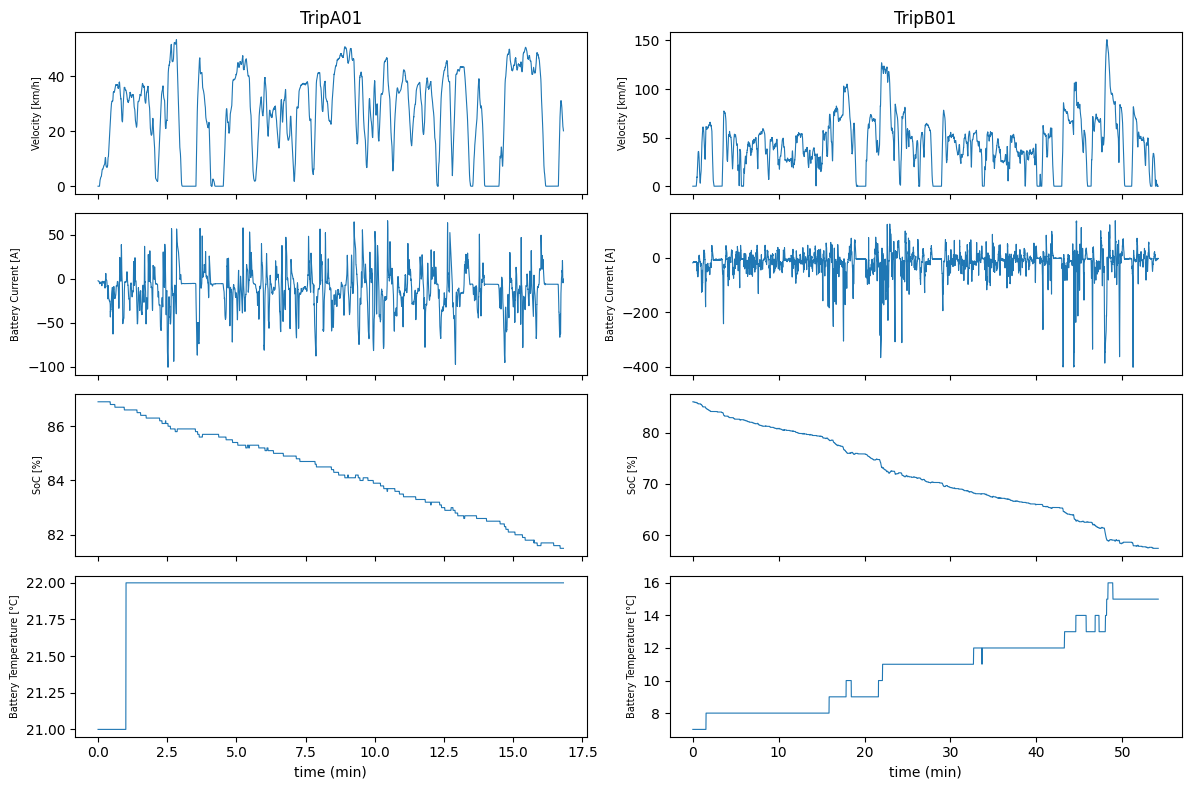

In [ ]:
# ==========================================
# 02.3 - REPRESENTATIVE SIGNALS (one summer and one winter trip)
# ==========================================
show = ['Velocity [km/h]', 'Battery Current [A]', 'SoC [%]', 'Battery Temperature [°C]']
names = [sorted(n for n in raw if n.startswith('TripA'))[0], sorted(n for n in raw if n.startswith('TripB'))[0]]
fig, ax = plt.subplots(len(show), 2, figsize=(12, 8), sharex='col')
for col, n in enumerate(names):
    d = raw[n]
    for r, c in enumerate(show):
        ax[r, col].plot(d['Time [s]'] / 60, d[c], linewidth=0.8)
        ax[r, col].set_ylabel(c, fontsize=7)
    ax[0, col].set_title(n); ax[-1, col].set_xlabel('time (min)')
plt.tight_layout()
plt.savefig(f'{PROJECT_ROOT}/results/figures/representative_signals_{tag}.png', dpi=200)
plt.show()

In [6]:
# ==========================================
# 03.1 - CLEAN EACH TRIP: fill the missing heater columns, trim trailing missing SoC
# ==========================================
HEATER_COLS = ['Heater Voltage [V]', 'Heater Current [A]']
FILL_MISSING_HEATER_WITH_ZERO = True   # decision for the 20 summer trips without heater V/I (False would drop those two inputs)

def prepare_trip(df):
    df = df.copy()
    if FILL_MISSING_HEATER_WITH_ZERO:
        for c in HEATER_COLS:
            if c not in df.columns:
                df[c] = 0.0
    valid_idx = df.index[df['SoC [%]'].notna()]                    # SoC is only missing at the END of some trips
    df = df.loc[valid_idx[0]:valid_idx[-1]].reset_index(drop=True)
    return df[['Time [s]'] + [c for c in ALL_COLS.values() if c in df.columns]]

trips = {name: prepare_trip(df) for name, df in raw.items()}

rows = []
for name, df in trips.items():
    used = [c for c in ALL_COLS.values() if c in df.columns]
    rows.append({'trip': name, 'rows': len(df), 'nans': int(df[used].isna().sum().sum()),
                 'missing_cols': [c for c in ALL_COLS.values() if c not in df.columns]})
clean = pd.DataFrame(rows)
print("Trips cleaned:", len(clean))
print("Trips still missing columns:", int((clean['missing_cols'].str.len() > 0).sum()))
print("Trips with NaNs:", int((clean.nans > 0).sum()), "| total NaNs:", int(clean.nans.sum()))
print("Shortest trip (rows):", int(clean.rows.min()), "(must hold at least one 256-step window)")
print("Total rows:", int(clean.rows.sum()))

Trips cleaned: 70
Trips still missing columns: 0
Trips with NaNs: 0 | total NaNs: 0
Shortest trip (rows): 2931 (must hold at least one 256-step window)
Total rows: 1064000


In [7]:
# ==========================================
# 03.2 - SMOOTH, DOWNSAMPLE TO 1 Hz, ELEVATION CHANGE
# ==========================================
SMOOTH_WINDOW = 10    # 1 s moving average at 10 Hz (as in the base paper)
DOWNSAMPLE = 10       # keep 1 sample per second (inferred from the paper's window count; documented assumption)
DT = 1.0              # seconds per step after downsampling

FEATURES = list(ALL_COLS.keys())           # 10 inputs, then 4 outputs
INPUT_KEYS, OUTPUT_KEYS = list(INPUT_COLS.keys()), list(OUTPUT_COLS.keys())
N_IN, N_OUT = len(INPUT_KEYS), len(OUTPUT_KEYS)
col_to_key = {v: k for k, v in ALL_COLS.items()}

def preprocess_trip(df):
    x = df[list(ALL_COLS.values())].rename(columns=col_to_key)[FEATURES].astype('float64')
    x = x.rolling(SMOOTH_WINDOW, min_periods=1).mean()        # 1 s moving average
    x = x.iloc[::DOWNSAMPLE].reset_index(drop=True)           # 10 Hz -> 1 Hz
    x['elevation'] = x['elevation'].diff().fillna(0.0)        # absolute elevation -> change per second
    return x.astype('float32')

proc = {name: preprocess_trip(df) for name, df in trips.items()}

lens = pd.Series({n: len(d) for n, d in proc.items()})
print("Trips processed:", len(proc))
print("Features (in order):", FEATURES)
print(f"Steps per trip: min={lens.min()}, median={int(lens.median())}, max={lens.max()}")
print("Total steps:", int(lens.sum()), "| expected windows at stride 1:", int((lens - WINDOW_SIZE + 1).clip(lower=0).sum()))
print("Trips shorter than one window:", [n for n, l in lens.items() if l < WINDOW_SIZE])

Trips processed: 70
Features (in order): ['current', 'throttle', 'velocity', 'elevation', 'heat_req', 'aircon', 'heater_v', 'heater_i', 'batt_temp', 'amb_temp', 'soc', 'voltage', 'torque', 'accel']
Steps per trip: min=294, median=1408, max=3822
Total steps: 106428 | expected windows at stride 1: 88578
Trips shorter than one window: []


In [8]:
# ==========================================
# 04.1 - TRIP-LEVEL SPLIT (before windowing)
# ==========================================
import json

SPLIT_SEED = 42
FRACS = (0.70, 0.15, 0.15)    # train / val / test

def split_trips(names, seed):
    names = sorted(names)
    rng = np.random.RandomState(seed)
    names = [names[i] for i in rng.permutation(len(names))]
    n = len(names)
    n_tr, n_va = round(FRACS[0] * n), round(FRACS[1] * n)
    return {'train': names[:n_tr], 'val': names[n_tr:n_tr + n_va], 'test': names[n_tr + n_va:]}

summer_names = sorted(n for n in proc if n.startswith('TripA'))
winter_names = sorted(n for n in proc if n.startswith('TripB'))
split = {'summer': split_trips(summer_names, SPLIT_SEED), 'winter': split_trips(winter_names, SPLIT_SEED)}

if TEST_MODE and NUM_TRIPS_PER_DOMAIN:        # test mode keeps a small subset of the SAME split
    for s in split:
        split[s] = {'train': split[s]['train'][:NUM_TRIPS_PER_DOMAIN], 'val': split[s]['val'][:2], 'test': split[s]['test'][:2]}

all_assigned = [t for s in split for k in split[s] for t in split[s][k]]
assert len(all_assigned) == len(set(all_assigned)), "A trip appears in more than one split!"

for s in split:
    for k in ['train', 'val', 'test']:
        print(f"{s:6s} {k:5s} ({len(split[s][k]):2d}): {split[s][k]}")
with open(f'{PROJECT_ROOT}/results/trip_split_{tag}.json', 'w') as f:
    json.dump(split, f, indent=2)
print("Saved split to results/")

summer train (22): ['TripA30', 'TripA16', 'TripA25', 'TripA18', 'TripA09', 'TripA10', 'TripA31', 'TripA26', 'TripA13', 'TripA01', 'TripA05', 'TripA17', 'TripA06', 'TripA14', 'TripA12', 'TripA24', 'TripA02', 'TripA03', 'TripA27', 'TripA04', 'TripA22', 'TripA28']
summer val   ( 5): ['TripA23', 'TripA19', 'TripA32', 'TripA21', 'TripA08']
summer test  ( 5): ['TripA11', 'TripA15', 'TripA29', 'TripA20', 'TripA07']
winter train (27): ['TripB34', 'TripB37', 'TripB05', 'TripB14', 'TripB31', 'TripB27', 'TripB07', 'TripB28', 'TripB25', 'TripB16', 'TripB18', 'TripB09', 'TripB17', 'TripB13', 'TripB20', 'TripB10', 'TripB33', 'TripB01', 'TripB26', 'TripB06', 'TripB12', 'TripB02', 'TripB38', 'TripB22', 'TripB03', 'TripB30', 'TripB36']
winter val   ( 6): ['TripB04', 'TripB35', 'TripB24', 'TripB32', 'TripB11', 'TripB23']
winter test  ( 5): ['TripB19', 'TripB21', 'TripB08', 'TripB15', 'TripB29']
Saved split to results/


In [9]:
# ==========================================
# 04.2 - SCALING (fit on TRAINING trips only) AND WINDOWING
# ==========================================
STEPS = WINDOW_SIZE        # 256 steps = 256 s
train_names = split['summer']['train'] + split['winter']['train']
train_all = pd.concat([proc[t] for t in train_names], ignore_index=True)

# One scaler for both seasons, fit on training trips only. Values are clipped to the 0.1 / 99.9 percentiles first so
# sensor glitches (e.g. a winter heater voltage of 1023 V) do not squash the rest of the range.
lo = train_all.quantile(0.001)
hi = train_all.quantile(0.999)
rng_ = (hi - lo).replace(0, 1.0)      # constant columns: avoid division by zero

def scale_df(df):
    x = df[FEATURES].clip(lower=lo, upper=hi, axis=1)
    return (2 * (x - lo) / rng_ - 1).values.astype('float32')

def inverse_scale(arr):
    """arr: (..., 14) in [-1, 1] -> real physical units."""
    return (arr + 1) / 2 * rng_.values.astype('float32') + lo.values.astype('float32')

def make_windows(arr, window, stride):
    if len(arr) < window:
        return np.empty((0, window, arr.shape[1]), dtype='float32')
    return np.stack([arr[i:i + window] for i in range(0, len(arr) - window + 1, stride)]).astype('float32')

data = {}
for s in split:
    data[s] = {}
    for k in ['train', 'val', 'test']:
        ws = [make_windows(scale_df(proc[t]), STEPS, STRIDE) for t in split[s][k]]
        data[s][k] = np.concatenate(ws) if ws else np.empty((0, STEPS, len(FEATURES)), 'float32')
        print(f"{s:6s} {k:5s}: windows = {data[s][k].shape}")

x = data['summer']['train']
print("\nTrain value range:", float(x.min()), "to", float(x.max()), "(should be within [-1, 1])")
roundtrip = inverse_scale(scale_df(proc[split['summer']['train'][0]]))
orig = proc[split['summer']['train'][0]][FEATURES].clip(lower=lo, upper=hi, axis=1).values
print("Inverse-scale round-trip max error:", float(np.abs(roundtrip - orig).max()))

with open(f'{PROJECT_ROOT}/results/scaler_{tag}.json', 'w') as f:
    json.dump({'features': FEATURES, 'lo': lo.tolist(), 'hi': hi.tolist()}, f, indent=2)
print("Saved scaler to results/")
print(f"Channel layout: inputs = channels 0..{N_IN-1}, outputs = channels {N_IN}..{N_IN+N_OUT-1}")

summer train: windows = (5823, 256, 14)
summer val  : windows = (1956, 256, 14)
summer test : windows = (1886, 256, 14)
winter train: windows = (9229, 256, 14)
winter val  : windows = (1609, 256, 14)
winter test : windows = (1667, 256, 14)

Train value range: -1.0 to 1.0 (should be within [-1, 1])
Inverse-scale round-trip max error: 4.57763671875e-05
Saved scaler to results/
Channel layout: inputs = channels 0..9, outputs = channels 10..13


In [10]:
# ==========================================
# 04.3 - SAVE THE WINDOWS
# ==========================================
out_path = f'{PROJECT_ROOT}/results/windows_{tag}.npz'
np.savez_compressed(out_path,
    summer_train=data['summer']['train'], summer_val=data['summer']['val'], summer_test=data['summer']['test'],
    winter_train=data['winter']['train'], winter_val=data['winter']['val'], winter_test=data['winter']['test'])
print("Saved:", out_path, "|", round(os.path.getsize(out_path) / 1e6, 2), "MB")

Saved: /content/drive/MyDrive/PI_CycleEV_Project/results/windows_full.npz | 6.02 MB


In [11]:
# ==========================================
# 04.4 - RELOAD THE SAVED WINDOWS AND SCALER (every model section below reads exactly these files)
# ==========================================
npz_path = f'{PROJECT_ROOT}/results/windows_{tag}.npz'
scaler_path = f'{PROJECT_ROOT}/results/scaler_{tag}.json'
for p in (npz_path, scaler_path):
    assert os.path.exists(p), f"Missing {p}"

z = np.load(npz_path)
data = {'summer': {k: z[f'summer_{k}'] for k in ['train', 'val', 'test']},
        'winter': {k: z[f'winter_{k}'] for k in ['train', 'val', 'test']}}

sc = json.load(open(scaler_path))
FEATURES = sc['features']
lo = np.array(sc['lo'], dtype='float32')        # from here on lo / hi are plain numpy arrays
hi = np.array(sc['hi'], dtype='float32')

def inverse_scale(arr):
    """[-1, 1] -> real physical units (needed for the physics losses and every plot in real units)."""
    return (arr + 1) / 2 * (hi - lo) + lo

N_IN, N_OUT = 10, 4
print({s: {k: v.shape for k, v in d.items()} for s, d in data.items()})

{'summer': {'train': (5823, 256, 14), 'val': (1956, 256, 14), 'test': (1886, 256, 14)}, 'winter': {'train': (9229, 256, 14), 'val': (1609, 256, 14), 'test': (1667, 256, 14)}}


In [12]:
# ==========================================
# 05.1 - BASELINE GENERATOR (TS-p2pGAN, paper Table 2)
# ==========================================
import tensorflow as tf
from tensorflow.keras import layers, Model

class ReflectPad1D(layers.Layer):
    """Keras has no built-in 1D reflection padding, so we make one."""
    def __init__(self, pad, **kwargs):
        super().__init__(**kwargs)
        self.pad = pad
    def call(self, x):
        return tf.pad(x, [[0, 0], [self.pad, self.pad], [0, 0]], mode="REFLECT")
    def get_config(self):
        return {**super().get_config(), "pad": self.pad}

def conv_bn_relu(x, filters, k, s):
    x = layers.Conv1D(filters, k, strides=s, padding="same")(x)
    x = layers.BatchNormalization()(x)
    return layers.ReLU()(x)

def resnet_block(x, filters=1024, dropout=0.3):
    skip = x
    x = ReflectPad1D(1)(x)
    x = layers.Conv1D(filters, 3, strides=1, padding="valid")(x)   # 18 -> 16
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.Dropout(dropout)(x)      # active only during training (verified: it is NOT kept on at inference)
    x = ReflectPad1D(1)(x)
    x = layers.Conv1D(filters, 3, strides=1, padding="valid")(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    return layers.Add()([skip, x])

def build_p2p_generator(in_ch=10, out_ch=4, length=256, n_res=9, dropout=0.3):
    inp = layers.Input(shape=(length, in_ch))

    # Front-end encoder (GF)
    x = ReflectPad1D(3)(inp)                                  # 256 -> 262
    x = layers.Conv1D(64, 7, strides=1, padding="valid")(x)   # -> 256
    x = layers.BatchNormalization()(x); x = layers.ReLU()(x)
    for f in [128, 256, 512, 1024]:                           # 256 -> 128 -> 64 -> 32 -> 16
        x = conv_bn_relu(x, f, k=3, s=2)

    # Residual blocks (GR)
    for _ in range(n_res):
        x = resnet_block(x, 1024, dropout)

    # Back-end decoder (GB)
    for f in [512, 256, 128, 64]:                             # 16 -> 32 -> 64 -> 128 -> 256
        x = layers.Conv1DTranspose(f, 3, strides=2, padding="same")(x)
        x = layers.BatchNormalization()(x); x = layers.ReLU()(x)

    x = ReflectPad1D(3)(x)                                    # 256 -> 262
    x = layers.Conv1D(out_ch, 7, strides=1, padding="valid")(x)  # -> 256
    out = layers.Activation("tanh")(x)                        # outputs in [-1, 1]
    return Model(inp, out, name="TS_p2pGAN_generator")

_g = build_p2p_generator()
assert _g.output_shape == (None, 256, 4)
print(f"Generator OK: output {_g.output_shape}, {_g.count_params():,} parameters")
del _g

Generator OK: output (None, 256, 4), 60,914,180 parameters


In [13]:
# ==========================================
# 05.2 - BASELINE DISCRIMINATOR (multi-scale, paper Table 3)
# ==========================================
def disc_branch(x):
    # Layer 1: no BatchNorm (as in the paper)
    x = layers.ZeroPadding1D(2)(x)
    x = layers.Conv1D(64, 4, strides=2)(x)
    x = layers.LeakyReLU(0.2)(x)
    # Layers 2-4: Conv + BatchNorm + LeakyReLU
    for f, s in [(128, 2), (256, 2), (512, 1)]:
        x = layers.ZeroPadding1D(2)(x)
        x = layers.Conv1D(f, 4, strides=s)(x)
        x = layers.BatchNormalization()(x)
        x = layers.LeakyReLU(0.2)(x)
    # Last layer: 1 channel = real/fake score for each patch
    x = layers.ZeroPadding1D(2)(x)
    x = layers.Conv1D(1, 4, strides=1)(x)
    return layers.Activation("sigmoid")(x)

def build_p2p_discriminator(in_ch=14, length=256):
    inp = layers.Input(shape=(length, in_ch))          # 10 inputs + 4 outputs stacked
    out1 = disc_branch(inp)                            # scale 1: full detail
    pooled = layers.AveragePooling1D(3, strides=2, padding="same")(inp)  # 256 -> 128
    out2 = disc_branch(pooled)                         # scale 2: half length
    return Model(inp, [out1, out2], name="TS_p2pGAN_discriminator")

_d = build_p2p_discriminator()
shapes = [tuple(o.shape) for o in _d.outputs]
assert shapes == [(None, 35, 1), (None, 19, 1)], shapes
print(f"Discriminator OK: outputs {shapes}, {_d.count_params():,} parameters")
del _d

Discriminator OK: outputs [(None, 35, 1), (None, 19, 1)], 1,396,610 parameters


In [14]:
# ==========================================
# 05.3 - BASELINE DATA: the SAME windows, split and scaler as the CycleGAN experiments
# ==========================================
train_xy = np.concatenate([data['summer']['train'], data['winter']['train']])    # paired model: both seasons together
val_xy   = np.concatenate([data['summer']['val'],   data['winter']['val']])
Xtr, Ytr = train_xy[:, :, :N_IN], train_xy[:, :, N_IN:]       # inputs = channels 0-9, targets = channels 10-13
Xva, Yva = val_xy[:, :, :N_IN],   val_xy[:, :, N_IN:]
del train_xy, val_xy
print("Baseline train:", Xtr.shape, "->", Ytr.shape, "| val:", Xva.shape, "->", Yva.shape)
print("Targets are:", FEATURES[N_IN:])

Baseline train: (15052, 256, 10) -> (15052, 256, 4) | val: (3565, 256, 10) -> (3565, 256, 4)
Targets are: ['soc', 'voltage', 'torque', 'accel']


In [15]:
# ==========================================
# 05.4 - BASELINE TRAINING RUNNER
# ==========================================
import time, random
import pandas as pd

# P2P_EPOCHS (number of baseline epochs) is set in cell 01.3
P2P_LR      = 6e-4                         # from the paper
LAMBDA_L1   = 100.0                        # pix2pix default: the paper does not state it
P2P_DECAY_FRACTION = 0.25                  # paper: lr decays to 0 over the last 200 of 800 epochs = last 25%

def run_baseline(run_name='ts_p2pgan', epochs=None, save_every=10):
    epochs = epochs or P2P_EPOCHS
    random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
    p2p_G = build_p2p_generator(); p2p_D = build_p2p_discriminator()
    g_opt = tf.keras.optimizers.Adam(P2P_LR, beta_1=0.5); d_opt = tf.keras.optimizers.Adam(P2P_LR, beta_1=0.5)
    bce = tf.keras.losses.BinaryCrossentropy()
    print(f"[{run_name}] generator {p2p_G.count_params():,} params | discriminator {p2p_D.count_params():,} params")

    @tf.function
    def step(x, y):
        with tf.GradientTape() as g_tape, tf.GradientTape() as d_tape:
            fake = p2p_G(x, training=True)
            d_real = p2p_D(tf.concat([x, y], axis=-1), training=True)
            d_fake = p2p_D(tf.concat([x, fake], axis=-1), training=True)
            d_loss = 0.0
            for r, f in zip(d_real, d_fake):
                d_loss += 0.5 * (bce(tf.ones_like(r), r) + bce(tf.zeros_like(f), f))
            g_adv = 0.0
            for f in d_fake:
                g_adv += bce(tf.ones_like(f), f)
            l1_loss = tf.reduce_mean(tf.abs(y - fake))
            g_loss = g_adv + LAMBDA_L1 * l1_loss
        g_opt.apply_gradients(zip(g_tape.gradient(g_loss, p2p_G.trainable_variables), p2p_G.trainable_variables))
        d_opt.apply_gradients(zip(d_tape.gradient(d_loss, p2p_D.trainable_variables), p2p_D.trainable_variables))
        return g_loss, d_loss, g_adv, l1_loss

    @tf.function
    def val_l1(x, y):
        return tf.reduce_mean(tf.abs(y - p2p_G(x, training=False)))

    ds = (tf.data.Dataset.from_tensor_slices((Xtr, Ytr)).shuffle(len(Xtr), seed=42)
          .batch(BATCH_SIZE, drop_remainder=True))
    assert len(Xtr) >= BATCH_SIZE, "Batch size is larger than the training set"

    history, t0 = [], time.time()
    decay_start = int(epochs * (1 - P2P_DECAY_FRACTION))
    for epoch in range(1, epochs + 1):
        lr = P2P_LR if epoch <= decay_start else P2P_LR * (epochs - epoch + 1) / (epochs - decay_start + 1)
        g_opt.learning_rate.assign(lr); d_opt.learning_rate.assign(lr)
        sums, n = np.zeros(4), 0
        for x, y in ds:
            sums += np.array([float(v) for v in step(x, y)]); n += 1
        sums /= n
        v_tot, v_cnt = 0.0, 0
        for s in range(0, len(Xva), BATCH_SIZE):
            xb, yb = Xva[s:s + BATCH_SIZE], Yva[s:s + BATCH_SIZE]
            v_tot += float(val_l1(xb, yb)) * len(xb); v_cnt += len(xb)
        row = dict(epoch=epoch, lr=lr, g_loss=sums[0], d_loss=sums[1], g_adv=sums[2], l1=sums[3], val_l1=v_tot / v_cnt)
        history.append(row)
        if not np.isfinite(row['g_loss']):
            raise RuntimeError(f'[{run_name}] training diverged (loss is NaN/inf) at epoch {epoch}. Check the data and the learning rate.')
        print(f"[{run_name}] ep {epoch:3d}/{epochs} | G {row['g_loss']:.3f} (adv {row['g_adv']:.3f}, L1 {row['l1']:.4f}) "
              f"| D {row['d_loss']:.3f} | val L1 {row['val_l1']:.4f} | lr {lr:.2e} | {time.time() - t0:.0f}s")
        if epoch % save_every == 0 or epoch == epochs:
            p2p_G.save_weights(f'{PROJECT_ROOT}/models/{run_name}_G_{tag}.weights.h5')
            pd.DataFrame(history).to_csv(f'{PROJECT_ROOT}/results/{run_name}_history_{tag}.csv', index=False)
    print(f"[{run_name}] saved weights and history.")
    return pd.DataFrame(history), p2p_G

def load_baseline(run_name='ts_p2pgan'):
    G = build_p2p_generator()
    G.load_weights(f'{PROJECT_ROOT}/models/{run_name}_G_{tag}.weights.h5')
    return G

In [16]:
# ==========================================
# 05.5 - TRAIN THE BASELINE (or load saved weights, see RETRAIN in cell 01.3)
# ==========================================
def have_baseline(run_name='ts_p2pgan'):
    return os.path.exists(f'{PROJECT_ROOT}/models/{run_name}_G_{tag}.weights.h5')

if RETRAIN or not have_baseline():
    hist_p2p, p2p_G = run_baseline('ts_p2pgan')
else:
    print(f"Found saved baseline weights ({tag}); loading them. Set RETRAIN_IN_FULL_MODE = True in cell 01.3 to retrain.")
    p2p_G = load_baseline('ts_p2pgan')
    hist_p2p = pd.read_csv(f'{PROJECT_ROOT}/results/ts_p2pgan_history_{tag}.csv')

Found saved baseline weights (full); loading them. Set RETRAIN_IN_FULL_MODE = True in cell 01.3 to retrain.


In [17]:
# ==========================================
# 05.6 - PREDICTION FUNCTION FOR SECTION 09
# ==========================================
baseline_predict = lambda x: p2p_G(x, training=False).numpy()    # (N, 256, 10) scaled inputs -> (N, 256, 4) scaled outputs
print("baseline_predict ready:", baseline_predict(Xva[:2]).shape)

baseline_predict ready: (2, 256, 4)


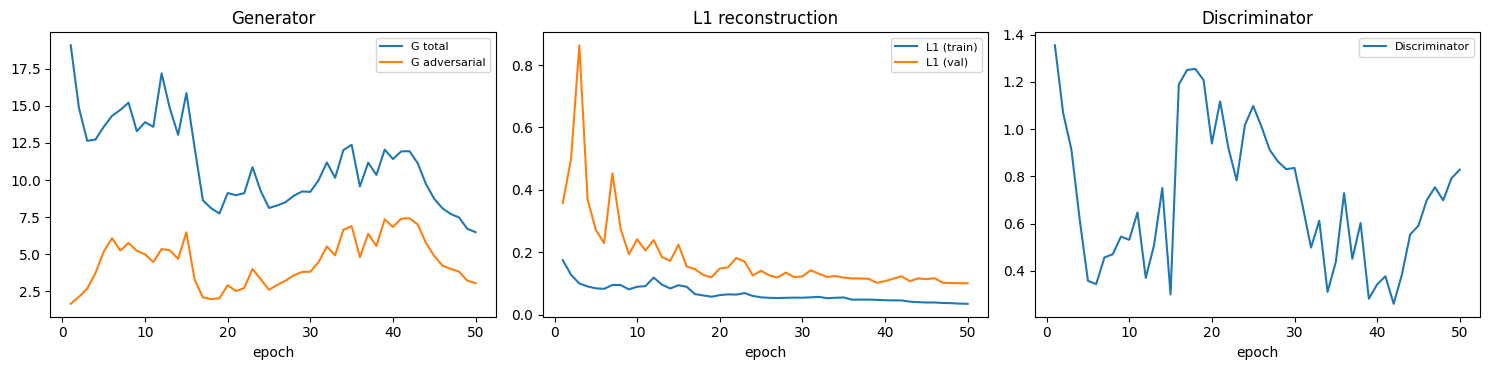

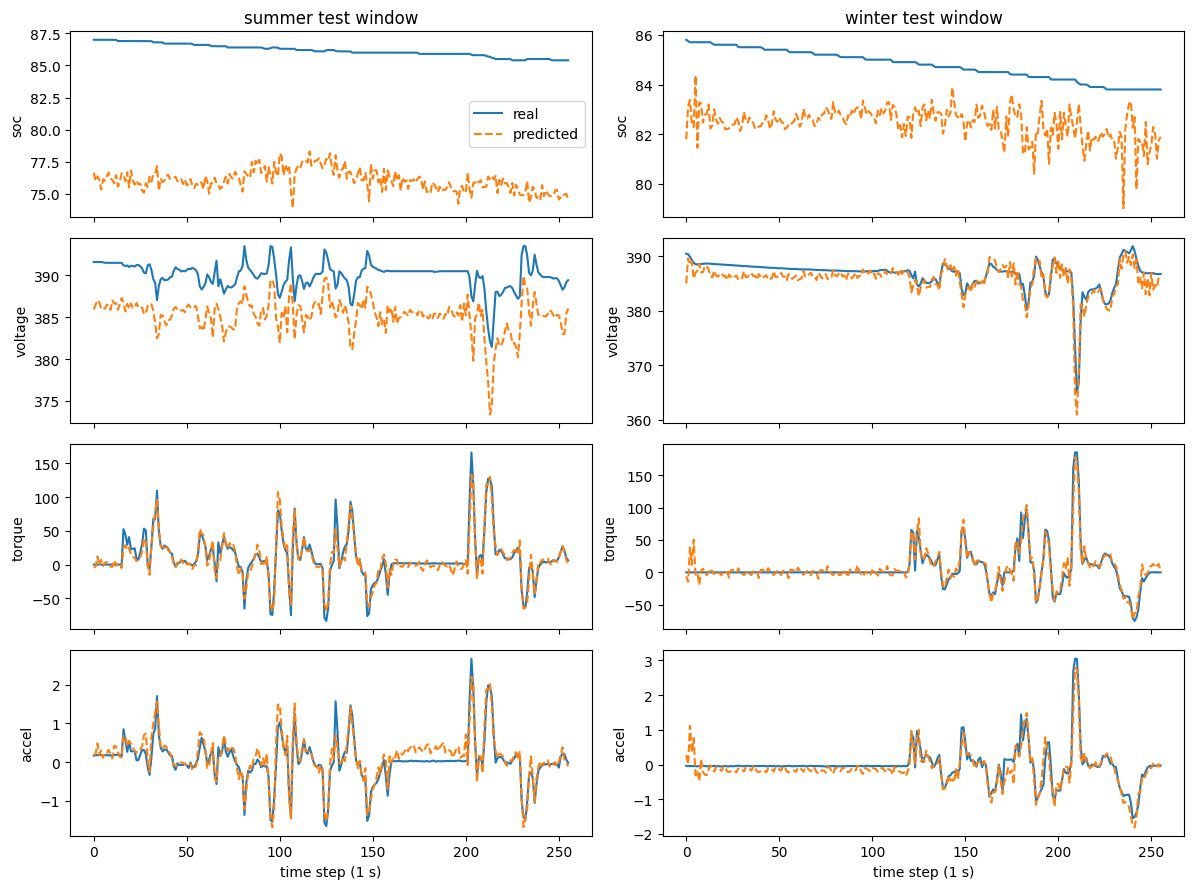

In [18]:
# ==========================================
# 05.7 - PLOTS: loss curves, and real vs predicted signals
# ==========================================
import matplotlib.pyplot as plt

h = hist_p2p
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].plot(h.epoch, h.g_loss, label='G total'); ax[0].plot(h.epoch, h.g_adv, label='G adversarial'); ax[0].set_title('Generator')
ax[1].plot(h.epoch, h.l1, label='L1 (train)'); ax[1].plot(h.epoch, h.val_l1, label='L1 (val)'); ax[1].set_title('L1 reconstruction')
ax[2].plot(h.epoch, h.d_loss, label='Discriminator'); ax[2].set_title('Discriminator')
for a_ in ax: a_.set_xlabel('epoch'); a_.legend(fontsize=8)
plt.tight_layout()
plt.savefig(f'{PROJECT_ROOT}/results/figures/ts_p2pgan_loss_curves_{tag}.png', dpi=200)
plt.show()

# One real test window per season: real targets vs the baseline's predictions (paired, so they can be compared directly)
x_test = np.concatenate([data['summer']['test'][:1], data['winter']['test'][:1]])
pred = p2p_G(x_test[:, :, :N_IN], training=False).numpy()
fig, ax = plt.subplots(N_OUT, 2, figsize=(12, 9), sharex=True)
for col, season in enumerate(['summer', 'winter']):
    real_phys = inverse_scale(x_test[col])
    pred_phys = inverse_scale(np.concatenate([x_test[col][:, :N_IN], pred[col]], axis=1))
    for r, name in enumerate(FEATURES[N_IN:]):
        c = N_IN + r
        ax[r, col].plot(real_phys[:, c], label='real')
        ax[r, col].plot(pred_phys[:, c], '--', label='predicted')
        ax[r, col].set_ylabel(name)
    ax[0, col].set_title(f'{season} test window'); ax[-1, col].set_xlabel('time step (1 s)')
ax[0, 0].legend()
plt.tight_layout()
plt.savefig(f'{PROJECT_ROOT}/results/figures/ts_p2pgan_real_vs_predicted_{tag}.png', dpi=200)
plt.show()

In [19]:
# ==========================================
# 06.1 - CYCLEGAN GENERATOR AND DISCRIMINATOR (1D, instance norm, ResNet blocks, PatchGAN)
# ==========================================
import os
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers

N_CH = 14
# CYCLE_EPOCHS (number of CycleGAN epochs) is set in cell 01.3
GEN_FILTERS    = 16 if TEST_MODE else 64
N_RES_BLOCKS   = 2 if TEST_MODE else 6
DISC_FILTERS   = 16 if TEST_MODE else 64
LAMBDA_CYCLE   = 10.0
LAMBDA_ID      = 5.0          # 0.5 * LAMBDA_CYCLE, as in the original CycleGAN
LR, BETA_1     = 2e-4, 0.5

class InstanceNorm1D(layers.Layer):
    """Normalizes each channel of each window over the time axis."""
    def __init__(self, epsilon=1e-5, **kwargs):
        super().__init__(**kwargs)
        self.epsilon = epsilon
    def build(self, input_shape):
        c = input_shape[-1]
        self.gamma = self.add_weight(name='gamma', shape=(c,), initializer='ones', trainable=True)
        self.beta = self.add_weight(name='beta', shape=(c,), initializer='zeros', trainable=True)
    def call(self, x):
        mean, var = tf.nn.moments(x, axes=[1], keepdims=True)
        x = (x - mean) * tf.math.rsqrt(var + self.epsilon)
        return x * self.gamma + self.beta

def res_block(x, filters):
    y = layers.Conv1D(filters, 3, padding='same')(x)
    y = InstanceNorm1D()(y)
    y = layers.ReLU()(y)
    y = layers.Conv1D(filters, 3, padding='same')(y)
    y = InstanceNorm1D()(y)
    return layers.Add()([x, y])

def build_generator(name, base=GEN_FILTERS, n_res=N_RES_BLOCKS):
    """Conv1D encoder -> ResNet blocks -> transposed-conv decoder (3 down / 3 up), tanh output."""
    inp = layers.Input((WINDOW_SIZE, N_CH))
    x = layers.Conv1D(base, 7, padding='same')(inp)
    x = InstanceNorm1D()(x); x = layers.ReLU()(x)
    f = base
    for _ in range(3):
        f *= 2
        x = layers.Conv1D(f, 3, strides=2, padding='same')(x)
        x = InstanceNorm1D()(x); x = layers.ReLU()(x)
    for _ in range(n_res):
        x = res_block(x, f)
    for _ in range(3):
        f //= 2
        x = layers.Conv1DTranspose(f, 3, strides=2, padding='same')(x)
        x = InstanceNorm1D()(x); x = layers.ReLU()(x)
    out = layers.Conv1D(N_CH, 7, padding='same', activation='tanh')(x)
    return tf.keras.Model(inp, out, name=name)

def build_discriminator(name, base=DISC_FILTERS):
    """1D PatchGAN: outputs a grid of real/fake scores, one per patch of the window."""
    inp = layers.Input((WINDOW_SIZE, N_CH))
    x = layers.Conv1D(base, 4, strides=2, padding='same')(inp)
    x = layers.LeakyReLU(0.2)(x)
    for mult in (2, 4):
        x = layers.Conv1D(base * mult, 4, strides=2, padding='same')(x)
        x = InstanceNorm1D()(x); x = layers.LeakyReLU(0.2)(x)
    x = layers.Conv1D(base * 8, 4, strides=1, padding='same')(x)
    x = InstanceNorm1D()(x); x = layers.LeakyReLU(0.2)(x)
    out = layers.Conv1D(1, 4, strides=1, padding='same')(x)
    return tf.keras.Model(inp, out, name=name)

print("Model definitions ready. CYCLE_EPOCHS =", CYCLE_EPOCHS)

Model definitions ready. CYCLE_EPOCHS = 100


In [20]:
# ==========================================
# 06.2 - HELPERS TO LOAD SAVED CYCLEGAN GENERATORS
# ==========================================
def have_run(run_name):
    return os.path.exists(f'{PROJECT_ROOT}/models/{run_name}_G_summer_to_winter_{tag}.weights.h5')

def load_generators(run_name):
    G_AB = build_generator('G_summer_to_winter'); G_BA = build_generator('G_winter_to_summer')
    G_AB.load_weights(f'{PROJECT_ROOT}/models/{run_name}_G_summer_to_winter_{tag}.weights.h5')
    G_BA.load_weights(f'{PROJECT_ROOT}/models/{run_name}_G_winter_to_summer_{tag}.weights.h5')
    return G_AB, G_BA
print("Generator loaders ready.")

Generator loaders ready.


In [21]:
# ==========================================
# 07.1 - PHYSICS-INFORMED LOSSES
# ==========================================
BATTERY_CAPACITY_AH = 60.0     # nominal BMW i3 (60 Ah)
DT = 1.0                       # seconds per step (data was downsampled to 1 Hz)

SOC_IDX      = FEATURES.index('soc')
CURRENT_IDX  = FEATURES.index('current')
VELOCITY_IDX = FEATURES.index('velocity')
ACCEL_IDX    = FEATURES.index('accel')

SCALER_LO    = tf.constant(lo, dtype=tf.float32)
SCALER_RANGE = tf.constant(hi - lo, dtype=tf.float32)

def inverse_scale_tf(x):
    """[-1, 1] -> real physical units (differentiable)."""
    return ((x + 1.0) / 2.0) * SCALER_RANGE + SCALER_LO

# ---- raw losses: all expect data in PHYSICAL units (% , A, km/h, m/s^2) ----
def soc_current_raw(x):
    """Total SOC change over the window vs. the change implied by integrated current (Coulomb counting).
    Dataset sign convention (verified): negative current = discharging."""
    soc, current = x[:, :, SOC_IDX], x[:, :, CURRENT_IDX]
    actual = soc[:, -1] - soc[:, 0]                                                    # % over the window
    charge_as = tf.reduce_sum((current[:, 1:] + current[:, :-1]) / 2.0, axis=1) * DT   # amp-seconds
    expected = charge_as * 100.0 / (BATTERY_CAPACITY_AH * 3600.0)                      # % over the window
    return tf.reduce_mean(tf.square(actual - expected))

def va_raw(x):
    """Acceleration vs. finite-difference derivative of velocity."""
    v_ms, a = x[:, :, VELOCITY_IDX] / 3.6, x[:, :, ACCEL_IDX]
    return tf.reduce_mean(tf.square((v_ms[:, 1:] - v_ms[:, :-1]) / DT - a[:, 1:]))

def range_raw(x):
    """Impossible values: SOC outside [0, 100] %, negative speed."""
    soc, vel = x[:, :, SOC_IDX], x[:, :, VELOCITY_IDX]
    return tf.reduce_mean(tf.nn.relu(-soc) ** 2 + tf.nn.relu(soc - 100.0) ** 2 + tf.nn.relu(-vel) ** 2)

# ---- fixed reference scales from REAL training windows (so the lambdas are comparable) ----
def _subsample(a, n=2000):
    return a[::max(1, len(a) // n)]

real_ref = np.concatenate([_subsample(data['summer']['train']), _subsample(data['winter']['train'])])
phys_ref = inverse_scale(real_ref)
SOC_REF = max(float(np.mean((phys_ref[:, -1, SOC_IDX] - phys_ref[:, 0, SOC_IDX]) ** 2)), 1e-6)   # mean squared real window SOC change
ACC_REF = max(float(np.mean(phys_ref[:, :, ACCEL_IDX] ** 2)), 1e-6)                              # mean squared real acceleration
print(f"Reference scales from {len(real_ref)} real windows: SOC_REF = {SOC_REF:.4f} (%^2), ACC_REF = {ACC_REF:.4f} (m/s^2)^2")

# ---- plausible window-level ranges, from REAL training windows of both seasons (1st to 99th percentile) ----
win_mean = phys_ref.mean(axis=1)                                            # (N, 14): average of each feature in each window
_lo, _hi = np.percentile(win_mean, 1, axis=0), np.percentile(win_mean, 99, axis=0)
_w = np.maximum(np.maximum(_hi - _lo, 0.05 * (hi - lo)), 1e-3)                # floor the band width (5% of the range, and never zero)
WB_LO, WB_HI, WB_W = (tf.constant(a, dtype=tf.float32) for a in (_lo, _hi, _w))
real_dsoc = phys_ref[:, -1, SOC_IDX] - phys_ref[:, 0, SOC_IDX]             # SOC change over each real window
_dlo, _dhi = np.percentile(real_dsoc, 1), np.percentile(real_dsoc, 99)
DS_LO, DS_HI, DS_W = float(_dlo), float(_dhi), float(max(_dhi - _dlo, 1.0))
print(f"Plausible window SOC change: {DS_LO:.1f} to {DS_HI:.1f} points | plausible window-mean current: "
      f"{_lo[CURRENT_IDX]:.1f} to {_hi[CURRENT_IDX]:.1f} A")
del real_ref, phys_ref

# ---- normalized losses: ~0 = consistent, ~1 = as bad as ignoring the physics ----
def soc_current_loss(x):           return soc_current_raw(x) / SOC_REF
def velocity_acceleration_loss(x): return va_raw(x) / ACC_REF
def window_range_raw(x):
    """Penalizes windows whose AVERAGE value of any feature, or whose total SOC change, lies outside the range seen in real
    windows. Zero inside the band. This catches physically self-consistent but absurd windows (e.g. a -230 A average current)."""
    m = tf.reduce_mean(x, axis=1)                                           # (batch, 14) window means in physical units
    exc = tf.nn.relu(WB_LO - m) + tf.nn.relu(m - WB_HI)
    pen = tf.reduce_sum(tf.square(exc / WB_W), axis=-1)                     # summed over features
    dsoc = x[:, -1, SOC_IDX] - x[:, 0, SOC_IDX]
    exc_d = tf.nn.relu(DS_LO - dsoc) + tf.nn.relu(dsoc - DS_HI)
    return tf.reduce_mean(pen + tf.square(exc_d / DS_W))

def range_penalty(x):              return range_raw(x) + window_range_raw(x)

def calculate_physics_losses(generated):
    """generated: model output in [-1, 1]. Converted to physical units before any physics is applied."""
    p = inverse_scale_tf(generated)
    return soc_current_loss(p), velocity_acceleration_loss(p), range_penalty(p)

print("Physics losses defined.")

Reference scales from 5220 real windows: SOC_REF = 8.7200 (%^2), ACC_REF = 0.3742 (m/s^2)^2
Plausible window SOC change: -7.9 to -0.1 points | plausible window-mean current: -68.8 to -1.7 A
Physics losses defined.


In [22]:
# ==========================================
# 07.2 - VERIFY THE PHYSICS LOSSES
# ==========================================
# ---- 1. Unit test on constructed windows (physical units, no scaler involved) ----
t = np.arange(WINDOW_SIZE, dtype='float32')
def make_window(current, vel_kmh_per_s, accel):
    x = np.zeros((1, WINDOW_SIZE, len(FEATURES)), 'float32')
    x[0, :, CURRENT_IDX] = current
    x[0, :, SOC_IDX] = 80.0 + np.cumsum(np.r_[0, np.full(WINDOW_SIZE - 1, current)]) * DT * 100.0 / (BATTERY_CAPACITY_AH * 3600.0)
    x[0, :, VELOCITY_IDX] = vel_kmh_per_s * t
    x[0, :, ACCEL_IDX] = accel
    return x

good = tf.constant(make_window(-100.0, 3.6, 1.0))
wrong_sign = make_window(-100.0, 3.6, 1.0); wrong_sign[0, :, CURRENT_IDX] = 100.0
print("UNIT TEST (raw losses)")
print("  consistent window : soc %.2e | va %.2e | range %.2e" % (
    float(soc_current_raw(good)), float(va_raw(good)), float(range_raw(good))))
print("  current sign flipped: soc %.2f   (must be much larger)" % float(soc_current_raw(tf.constant(wrong_sign))))
print("  accel set to 0      : va  %.3f  (expected 1.000)" % float(va_raw(tf.constant(make_window(-100.0, 3.6, 0.0)))))

# ---- 2. Real windows vs. broken-physics controls (normalized losses) ----
def report(x_scaled, label):
    p = inverse_scale_tf(tf.convert_to_tensor(x_scaled, tf.float32))
    print(f"  {label:44s} soc {float(soc_current_loss(p)):8.4f} | va {float(velocity_acceleration_loss(p)):8.4f} | range {float(range_penalty(p)):.5f}")

def swap_channel(x, idx):          # channel taken from a different window = broken physics
    y = x.copy(); y[:, :, idx] = y[::-1, :, idx]; return y

print("\nREAL DATA REPORT (normalized: ~0 consistent, ~1 ignores the physics)")
for name in ['summer', 'winter']:
    arr = _subsample(data[name]['train'], 256)
    report(arr, f'REAL {name}')
    report(swap_channel(arr, SOC_IDX),   f'   control: {name} SOC from other windows')
    report(swap_channel(arr, ACCEL_IDX), f'   control: {name} accel from other windows')
print("\nIf a REAL row is not clearly below its control rows, that loss cannot tell real from broken physics.")

UNIT TEST (raw losses)
  consistent window : soc 3.64e-12 | va 2.73e-11 | range 0.00e+00
  current sign flipped: soc 557.48   (must be much larger)
  accel set to 0      : va  1.000  (expected 1.000)

REAL DATA REPORT (normalized: ~0 consistent, ~1 ignores the physics)
  REAL summer                                  soc   0.0100 | va   0.1856 | range 0.00071
     control: summer SOC from other windows    soc   0.3637 | va   0.1856 | range 0.00071
     control: summer accel from other windows  soc   0.0100 | va   1.9999 | range 0.00071
  REAL winter                                  soc   0.0332 | va   0.1624 | range 0.07625
     control: winter SOC from other windows    soc   1.1984 | va   0.1624 | range 0.07625
     control: winter accel from other windows  soc   0.0332 | va   1.8578 | range 0.07625

If a REAL row is not clearly below its control rows, that loss cannot tell real from broken physics.


In [23]:
# ==========================================
# 08.1 - EXPERIMENT RUNNER (fresh models every run)
# ==========================================
import time, random
import pandas as pd

def adv_real(pred): return tf.reduce_mean(tf.square(pred - 1.0))   # least-squares GAN
def adv_fake(pred): return tf.reduce_mean(tf.square(pred))
def l1(a, b):       return tf.reduce_mean(tf.abs(a - b))

def make_ds(arr):
    return (tf.data.Dataset.from_tensor_slices(arr).shuffle(len(arr), seed=42)
            .batch(BATCH_SIZE, drop_remainder=True).repeat())

def run_experiment(run_name, lam_soc, lam_va, lam_range, epochs=None, save_every=10, resume=False):
    """Trains a CycleGAN from scratch. lam_* = 0 turns a physics term off (standard CycleGAN = all three 0).
    All physics terms are logged every epoch, even when their weight is 0."""
    epochs = epochs or CYCLE_EPOCHS
    random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)       # same start for every run

    G_AB = build_generator('G_summer_to_winter'); G_BA = build_generator('G_winter_to_summer')
    D_A  = build_discriminator('D_summer');       D_B  = build_discriminator('D_winter')
    opt_G = tf.keras.optimizers.Adam(LR, beta_1=BETA_1)
    opt_D = tf.keras.optimizers.Adam(LR, beta_1=BETA_1)
    G_VARS = G_AB.trainable_variables + G_BA.trainable_variables
    D_VARS = D_A.trainable_variables + D_B.trainable_variables
    print(f"[{run_name}] lambdas: soc={lam_soc}, va={lam_va}, range={lam_range} | "
          f"params: G {G_AB.count_params():,} each, D {D_A.count_params():,} each")
    history, start = [], 1
    if resume:                                          # continue from the last saved checkpoint (generators only)
        G_AB.load_weights(f'{PROJECT_ROOT}/models/{run_name}_G_summer_to_winter_{tag}.weights.h5')
        G_BA.load_weights(f'{PROJECT_ROOT}/models/{run_name}_G_winter_to_summer_{tag}.weights.h5')
        history = pd.read_csv(f'{PROJECT_ROOT}/results/{run_name}_history_{tag}.csv').to_dict('records')
        start = len(history) + 1
        print(f"[{run_name}] RESUMING from epoch {start} (generators restored; discriminators and optimisers are fresh)")

    @tf.function
    def train_step(real_a, real_b):
        with tf.GradientTape(persistent=True) as tape:
            fake_b = G_AB(real_a, training=True); fake_a = G_BA(real_b, training=True)
            cyc_a  = G_BA(fake_b, training=True); cyc_b  = G_AB(fake_a, training=True)
            same_a = G_BA(real_a, training=True); same_b = G_AB(real_b, training=True)
            d_a_real, d_a_fake = D_A(real_a, training=True), D_A(fake_a, training=True)
            d_b_real, d_b_fake = D_B(real_b, training=True), D_B(fake_b, training=True)

            g_adv    = adv_real(d_b_fake) + adv_real(d_a_fake)
            cycle    = l1(real_a, cyc_a) + l1(real_b, cyc_b)
            identity = l1(real_a, same_a) + l1(real_b, same_b)

            soc_a, va_a, rng_a = calculate_physics_losses(fake_a)
            soc_b, va_b, rng_b = calculate_physics_losses(fake_b)
            p_soc, p_va, p_rng = (soc_a + soc_b) / 2, (va_a + va_b) / 2, (rng_a + rng_b) / 2

            g_total = (g_adv + LAMBDA_CYCLE * cycle + LAMBDA_ID * identity
                       + lam_soc * p_soc + lam_va * p_va + lam_range * p_rng)
            d_a_loss = 0.5 * (adv_real(d_a_real) + adv_fake(d_a_fake))
            d_b_loss = 0.5 * (adv_real(d_b_real) + adv_fake(d_b_fake))
            d_total = d_a_loss + d_b_loss
        opt_G.apply_gradients(zip(tape.gradient(g_total, G_VARS), G_VARS))
        opt_D.apply_gradients(zip(tape.gradient(d_total, D_VARS), D_VARS))
        del tape
        return {'g_total': g_total, 'g_adv': g_adv, 'cycle': cycle, 'identity': identity,
                'phys_soc': p_soc, 'phys_va': p_va, 'phys_range': p_rng, 'd_a': d_a_loss, 'd_b': d_b_loss}

    @tf.function
    def val_step(real_a, real_b):
        fake_b = G_AB(real_a, training=False); fake_a = G_BA(real_b, training=False)
        cyc = l1(real_a, G_BA(fake_b, training=False)) + l1(real_b, G_AB(fake_a, training=False))
        idn = l1(real_a, G_BA(real_a, training=False)) + l1(real_b, G_AB(real_b, training=False))
        sa, va, _ = calculate_physics_losses(fake_a); sb, vb, _ = calculate_physics_losses(fake_b)
        return cyc, idn, (sa + sb) / 2, (va + vb) / 2

    def validate():                                     # in chunks, so full mode does not run out of memory
        va_, vb_ = data['summer']['val'], data['winter']['val']
        n = min(len(va_), len(vb_)); tot = np.zeros(4); cnt = 0
        for s in range(0, n, BATCH_SIZE):
            a, b = tf.constant(va_[s:s + BATCH_SIZE]), tf.constant(vb_[s:s + BATCH_SIZE])
            tot += np.array([float(v) for v in val_step(a, b)]) * a.shape[0]; cnt += a.shape[0]
        return tot / cnt

    train_a, train_b = data['summer']['train'], data['winter']['train']
    steps = min(len(train_a), len(train_b)) // BATCH_SIZE
    assert steps > 0, "Batch size is larger than the smaller training set"
    it = iter(tf.data.Dataset.zip((make_ds(train_a), make_ds(train_b))))     # shuffled independently = unpaired

    t0 = time.time()
    for epoch in range(start, epochs + 1):
        sums = {}
        for _ in range(steps):
            a, b = next(it)
            for k, v in train_step(a, b).items(): sums[k] = sums.get(k, 0.0) + float(v)
        row = {k: v / steps for k, v in sums.items()}
        if not np.isfinite(row['g_total']):
            raise RuntimeError(f'[{run_name}] training diverged (loss is NaN/inf) at epoch {epoch}. Check the data, the scaler and the physics reference values.')
        v_cyc, v_id, v_soc, v_va = validate()
        row.update({'epoch': epoch, 'val_cycle': v_cyc, 'val_identity': v_id, 'val_phys_soc': v_soc, 'val_phys_va': v_va})
        history.append(row)
        print(f"[{run_name}] ep {epoch:3d}/{epochs} | G {row['g_total']:.3f} (adv {row['g_adv']:.3f} cyc {row['cycle']:.3f} id {row['identity']:.3f}) "
              f"| phys soc {row['phys_soc']:.4f} va {row['phys_va']:.4f} rng {row['phys_range']:.4f} "
              f"| D {row['d_a']:.3f}/{row['d_b']:.3f} | val cyc {v_cyc:.3f} soc {v_soc:.4f} va {v_va:.4f} | {time.time() - t0:.0f}s")
        if epoch % save_every == 0 or epoch == epochs:
            G_AB.save_weights(f'{PROJECT_ROOT}/models/{run_name}_G_summer_to_winter_{tag}.weights.h5')
            G_BA.save_weights(f'{PROJECT_ROOT}/models/{run_name}_G_winter_to_summer_{tag}.weights.h5')
            pd.DataFrame(history).to_csv(f'{PROJECT_ROOT}/results/{run_name}_history_{tag}.csv', index=False)
    print(f"[{run_name}] saved weights and history.")
    return pd.DataFrame(history), G_AB, G_BA

def run_or_load(run_name, lam_soc, lam_va, lam_range):
    """Train from scratch (test mode, or RETRAIN) or load the saved generators and history."""
    if RETRAIN or not have_run(run_name):
        return run_experiment(run_name, lam_soc, lam_va, lam_range)
    print(f"[{run_name}] found saved weights ({tag}); loading them. Set RETRAIN_IN_FULL_MODE = True in cell 01.3 to retrain.")
    G_AB, G_BA = load_generators(run_name)
    return pd.read_csv(f'{PROJECT_ROOT}/results/{run_name}_history_{tag}.csv'), G_AB, G_BA

In [24]:
# ==========================================
# 08.1a - CHECK THE TRAINED RUNS (each must show 100 epochs)
# ==========================================
import pandas as pd
for r in ['cyclegan_nophys', 'picycleev', 'abl_no_soc', 'abl_no_va', 'abl_no_range']:
    d = pd.read_csv(f'{PROJECT_ROOT}/results/{r}_history_full.csv')
    print(f"{r:18s} {len(d):3d} epochs | last {int(d['epoch'].iloc[-1])} | unique {d['epoch'].is_unique}")

cyclegan_nophys    100 epochs | last 100 | unique True
picycleev          100 epochs | last 100 | unique True
abl_no_soc         100 epochs | last 100 | unique True
abl_no_va          100 epochs | last 100 | unique True
abl_no_range       100 epochs | last 100 | unique True


In [25]:
# ==========================================
# 08.1b - CHECK THE SAVED WEIGHTS (matters when RETRAIN is False: missing runs would be TRAINED by the cells below)
# ==========================================
need = ['cyclegan_nophys', 'picycleev'] + (['abl_no_soc', 'abl_no_va', 'abl_no_range'] if RUN_ABLATIONS else [])
missing = [r for r in need if not have_run(r)] + ([] if have_baseline() else ['ts_p2pgan'])
if RETRAIN:
    print("RETRAIN is True: the cells below TRAIN every model (hours). Set RETRAIN_IN_FULL_MODE = False in 01.3 to reuse saved weights.")
elif missing:
    print("WARNING - no saved weights for:", missing, "-> the cells below will TRAIN them (about 1 hour per CycleGAN run).")
else:
    print("All saved weights found: the cells below only load them.")

All saved weights found: the cells below only load them.


In [27]:
# ==========================================
# 08.2 - E2 CONTROL: standard CycleGAN (all physics weights = 0)
# ==========================================
hist_e2, G_AB_e2, G_BA_e2 = run_or_load('cyclegan_nophys', 0.0, 0.0, 0.0)

[cyclegan_nophys] found saved weights (full); loading them. Set RETRAIN_IN_FULL_MODE = True in cell 01.3 to retrain.


In [28]:
# ==========================================
# 08.3 - E3: PI-CycleEV (physics weights are untuned starting values)
# ==========================================
LAM_SOC, LAM_VA, LAM_RANGE = 0.4, 0.03, 5.0
hist_pi, G_AB_pi, G_BA_pi = run_or_load('picycleev', LAM_SOC, LAM_VA, LAM_RANGE)

[picycleev] found saved weights (full); loading them. Set RETRAIN_IN_FULL_MODE = True in cell 01.3 to retrain.


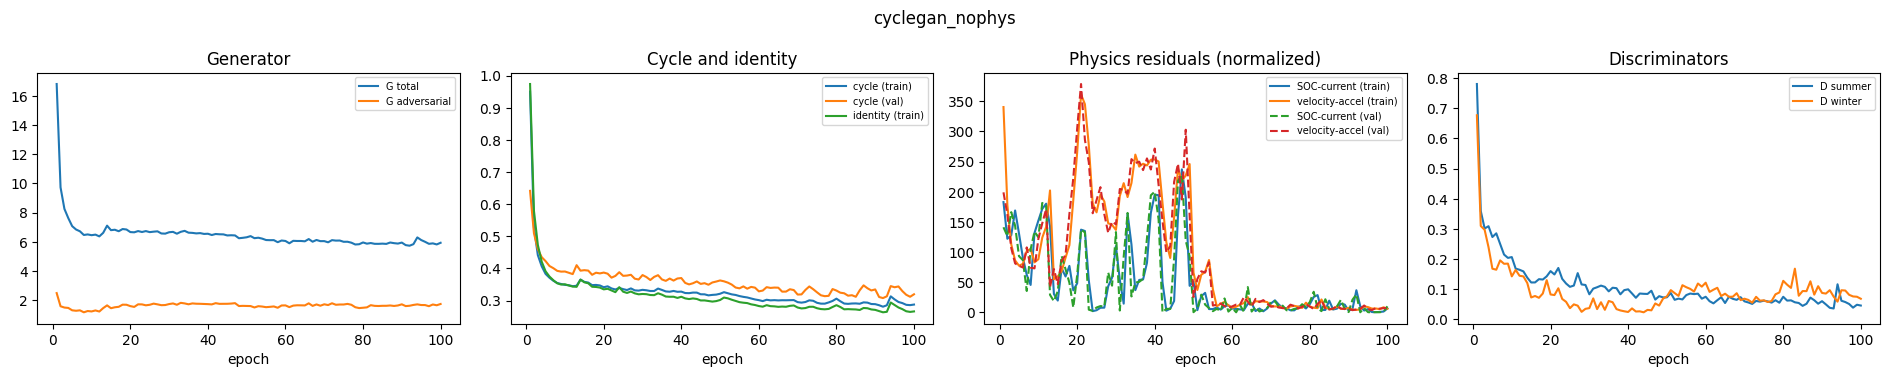

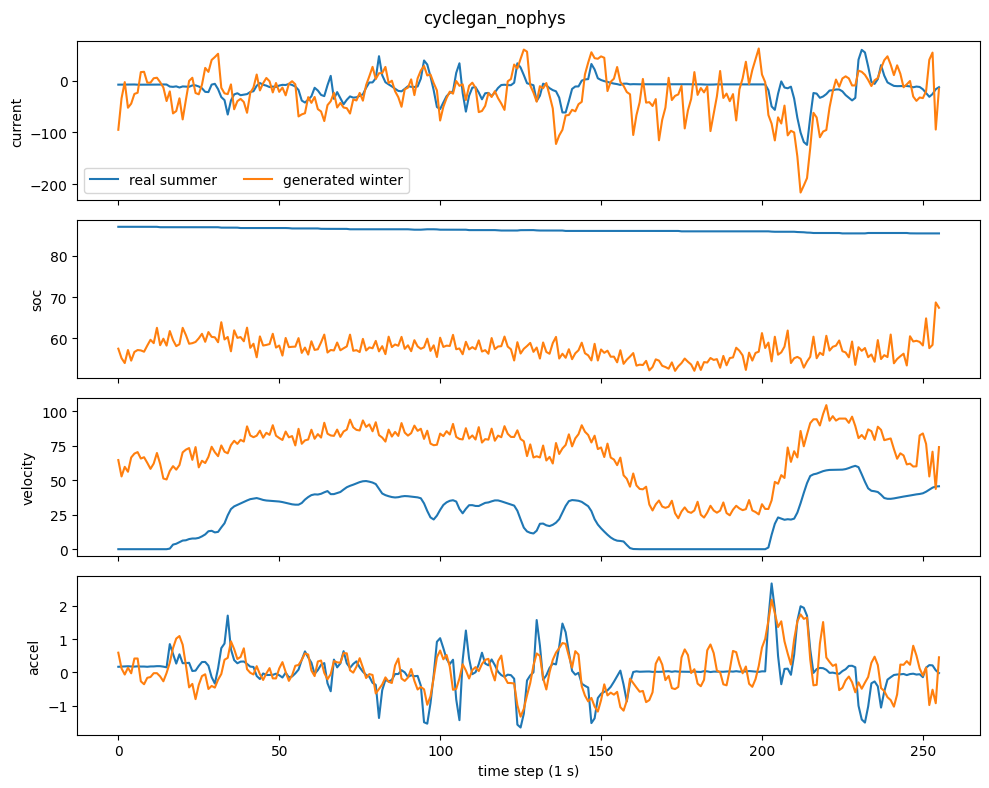

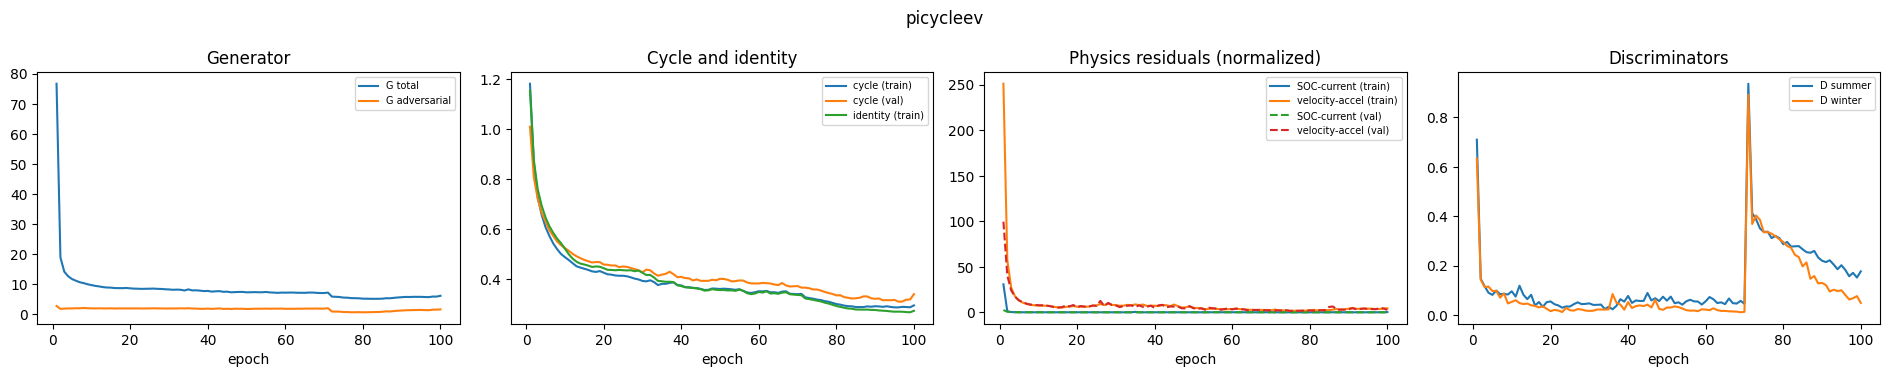

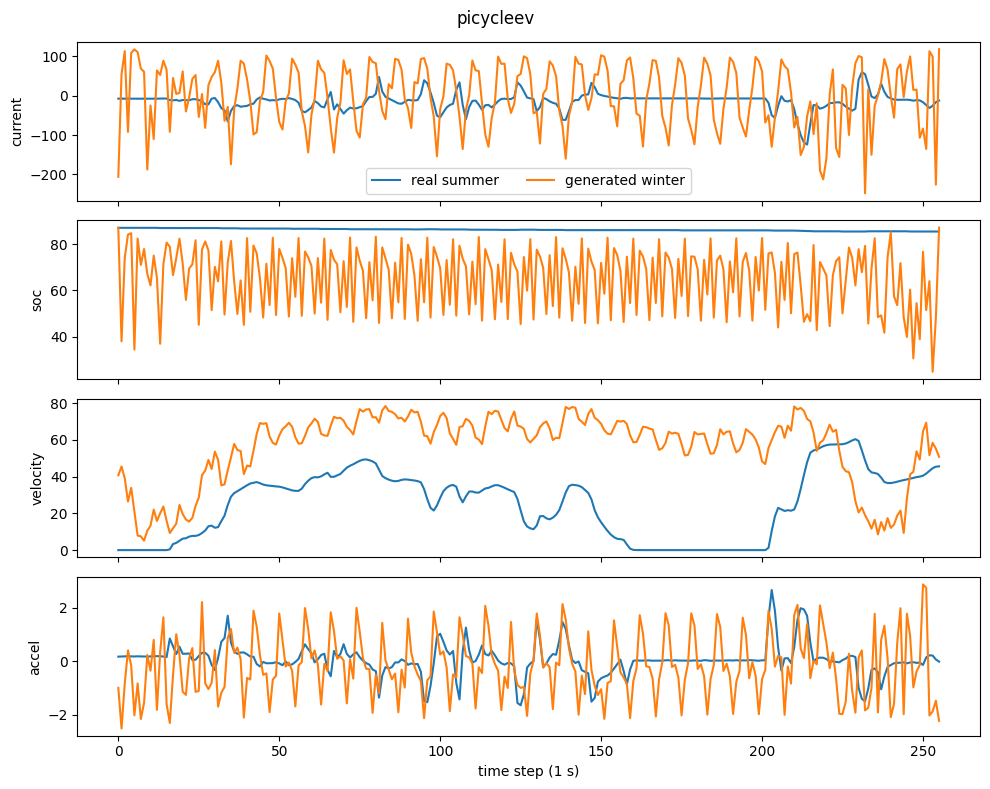

In [29]:
# ==========================================
# 08.4 - PLOTS (loss curves + sample translation) for E2 and E3
# ==========================================
def plot_run(h, G_AB, G_BA, run_name):
    fig, ax = plt.subplots(1, 4, figsize=(19, 3.8))
    ax[0].plot(h.epoch, h.g_total, label='G total'); ax[0].plot(h.epoch, h.g_adv, label='G adversarial'); ax[0].set_title('Generator')
    ax[1].plot(h.epoch, h.cycle, label='cycle (train)'); ax[1].plot(h.epoch, h.val_cycle, label='cycle (val)')
    ax[1].plot(h.epoch, h.identity, label='identity (train)'); ax[1].set_title('Cycle and identity')
    ax[2].plot(h.epoch, h.phys_soc, label='SOC-current (train)'); ax[2].plot(h.epoch, h.phys_va, label='velocity-accel (train)')
    ax[2].plot(h.epoch, h.val_phys_soc, '--', label='SOC-current (val)'); ax[2].plot(h.epoch, h.val_phys_va, '--', label='velocity-accel (val)')
    ax[2].set_title('Physics residuals (normalized)')
    ax[3].plot(h.epoch, h.d_a, label='D summer'); ax[3].plot(h.epoch, h.d_b, label='D winter'); ax[3].set_title('Discriminators')
    for a_ in ax: a_.set_xlabel('epoch'); a_.legend(fontsize=7)
    plt.suptitle(run_name)
    plt.tight_layout()
    plt.savefig(f'{PROJECT_ROOT}/results/figures/{run_name}_loss_curves_{tag}.png', dpi=200)
    plt.show()

    sample = data['summer']['test'][:1]
    to_winter = G_AB(sample, training=False).numpy()
    show = ['current', 'soc', 'velocity', 'accel']
    fig, ax = plt.subplots(len(show), 1, figsize=(10, 8), sharex=True)
    for i, f in enumerate(show):
        c = FEATURES.index(f)
        ax[i].plot(inverse_scale(sample[0])[:, c], label='real summer')
        ax[i].plot(inverse_scale(to_winter[0])[:, c], label='generated winter')
        ax[i].set_ylabel(f)
    ax[0].legend(ncol=2); ax[-1].set_xlabel('time step (1 s)')
    plt.suptitle(run_name)
    plt.tight_layout()
    plt.savefig(f'{PROJECT_ROOT}/results/figures/{run_name}_sample_translation_{tag}.png', dpi=200)
    plt.show()

plot_run(hist_e2, G_AB_e2, G_BA_e2, 'cyclegan_nophys')
plot_run(hist_pi, G_AB_pi, G_BA_pi, 'picycleev')

In [30]:
# ==========================================
# 08.5 - E2 vs E3 at the last epoch
# ==========================================
cols = ['cycle', 'identity', 'phys_soc', 'phys_va', 'val_cycle', 'val_phys_soc', 'val_phys_va', 'd_a', 'd_b']
compare = pd.DataFrame({'E2 CycleGAN (no physics)': hist_e2.iloc[-1][cols],
                        'E3 PI-CycleEV':            hist_pi.iloc[-1][cols]})
compare['E3 minus E2'] = compare['E3 PI-CycleEV'] - compare['E2 CycleGAN (no physics)']
compare['E3 / E2']     = compare['E3 PI-CycleEV'] / compare['E2 CycleGAN (no physics)']
display(compare.round(4))
compare.to_csv(f'{PROJECT_ROOT}/results/e2_vs_e3_last_epoch_{tag}.csv')
print("Saved comparison table.")

,E2 CycleGAN (no physics),E3 PI-CycleEV,E3 minus E2,E3 / E2
cycle,0.2875,0.2944,0.0069,1.0240
identity,0.2662,0.2728,0.0066,1.0249
phys_soc,6.3266,0.2007,-6.1258,0.0317
phys_va,6.0096,4.3774,-1.6322,0.7284
val_cycle,0.3195,0.3394,0.0199,1.0623
val_phys_soc,9.9755,0.0113,-9.9642,0.0011
val_phys_va,7.1680,2.6074,-4.5606,0.3638
d_a,0.0455,0.1765,0.1310,3.8818
d_b,0.0680,0.0486,-0.0194,0.7142


Saved comparison table.


In [35]:
# ==========================================
# 09.1 - EVALUATION HELPERS
# ==========================================
try:
    from tslearn.metrics import dtw
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, '-m', 'pip', 'install', 'tslearn', '-q'])
    from tslearn.metrics import dtw

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import wasserstein_distance
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

OUT_NAMES = ['soc', 'voltage', 'torque', 'accel']                 # the 4 target signals of the base paper
OUT_IDX   = [FEATURES.index(f) for f in OUT_NAMES]
N_DTW     = 30 if TEST_MODE else 100      # windows used for DTW (it is slow)
N_EMBED   = 300 if TEST_MODE else 1000    # windows per group in the PCA / t-SNE plots
EVAL_SEED = 42
RANGE     = np.maximum(hi - lo, 1e-6)                       # physical range of each feature (for "% of range" metrics)

METRICS = []                              # every number goes here, then to metrics.csv
def record(experiment, direction, metric, value, channel='all'):
    METRICS.append(dict(experiment=experiment, direction=direction, channel=channel,
                        metric=metric, value=float(value), mode=tag))

def generate(G, x, bs=128):
    return np.concatenate([G(x[i:i + bs], training=False).numpy() for i in range(0, len(x), bs)])

# ---- paired metrics. Data are scaled to [-1, 1], so /2 turns an error into a fraction of the feature range ----
def rmse_pct(a, b, idx): return float(np.sqrt(np.mean(((a[:, :, idx] - b[:, :, idx]) / 2) ** 2)) * 100)
def mae_pct(a, b, idx):  return float(np.mean(np.abs(a[:, :, idx] - b[:, :, idx]) / 2) * 100)
def dtw_pct(a, b, idx, n=N_DTW):
    sel = np.linspace(0, len(a) - 1, min(n, len(a))).astype(int)
    vals = [dtw(a[i, :, c] / 2, b[i, :, c] / 2) / np.sqrt(a.shape[1]) for i in sel for c in np.atleast_1d(idx)]
    return float(np.mean(vals) * 100)

def level_shape_metrics(experiment, direction, real, synth):
    """Splits each signal's error into a constant LEVEL offset per window and the within-window SHAPE error.
    flat_ref_shape = the shape error of a prediction that is flat inside each window (the bar a model must beat)."""
    for name, c in zip(OUT_NAMES, OUT_IDX):
        r, s_ = real[:, :, c], synth[:, :, c]
        rm, sm = r.mean(axis=1, keepdims=True), s_.mean(axis=1, keepdims=True)
        record(experiment, direction, 'level_L1_%',          np.mean(np.abs(rm - sm)) / 2 * 100, name)
        record(experiment, direction, 'shape_L1_%',          np.mean(np.abs((r - rm) - (s_ - sm))) / 2 * 100, name)
        record(experiment, direction, 'flat_ref_shape_L1_%', np.mean(np.abs(r - rm)) / 2 * 100, name)

def paired_metrics(experiment, direction, real, synth, include_all=True):
    level_shape_metrics(experiment, direction, real, synth)
    for name, c in zip(OUT_NAMES, OUT_IDX):
        record(experiment, direction, 'RMSE_%', rmse_pct(real, synth, c), name)
        record(experiment, direction, 'MAE_%',  mae_pct(real, synth, c), name)
        record(experiment, direction, 'DTW_%',  dtw_pct(real, synth, c), name)
    if include_all:
        allc = list(range(real.shape[2]))
        record(experiment, direction, 'RMSE_%', rmse_pct(real, synth, allc), 'all14')
        record(experiment, direction, 'MAE_%',  mae_pct(real, synth, allc), 'all14')

# ---- distribution metrics, in real physical units ----
def flat_phys(windows, max_rows=200000):
    p = inverse_scale(windows).reshape(-1, windows.shape[2])
    if len(p) > max_rows:
        p = p[np.random.RandomState(EVAL_SEED).choice(len(p), max_rows, replace=False)]
    return p

def distribution_metrics(experiment, direction, real_t, synth_t):
    pr, ps = flat_phys(real_t), flat_phys(synth_t)
    for j, f in enumerate(FEATURES):
        record(experiment, direction, 'mean_abs_diff_%range', abs(pr[:, j].mean() - ps[:, j].mean()) / RANGE[j] * 100, f)
        record(experiment, direction, 'std_abs_diff_%range',  abs(pr[:, j].std() - ps[:, j].std()) / RANGE[j] * 100, f)
        record(experiment, direction, 'wasserstein_%range',   wasserstein_distance(pr[:, j], ps[:, j]) / RANGE[j] * 100, f)
    # diversity: spread of the per-window averages, generated / real (about 1 = as varied as real data, near 0 = collapsed to a constant)
    wr, ws = inverse_scale(real_t).mean(axis=1), inverse_scale(synth_t).mean(axis=1)
    ratio = ws.std(axis=0) / np.maximum(wr.std(axis=0), 1e-9)
    for j, f in enumerate(FEATURES):
        record(experiment, direction, 'window_mean_std_ratio', ratio[j], f)
    off = ~np.eye(len(FEATURES), dtype=bool)
    with np.errstate(invalid='ignore', divide='ignore'):
        diff = np.abs(np.corrcoef(pr.T) - np.corrcoef(ps.T))
    record(experiment, direction, 'corr_matrix_mean_abs_diff', np.nanmean(diff[off]))
    # same comparison restricted to the 4 target signals (fair for the baseline, whose 10 inputs are copied from real data)
    o = OUT_IDX
    with np.errstate(invalid='ignore', divide='ignore'):
        d4 = np.abs(np.corrcoef(pr[:, o].T) - np.corrcoef(ps[:, o].T))
    record(experiment, direction, 'corr_outputs_mean_abs_diff', np.nanmean(d4[~np.eye(len(o), dtype=bool)]))

# ---- physics residuals (the normalized losses from Section 07; 0 = consistent, 1 = ignores the physics) ----
def physics_residuals(windows, bs=256):
    s = v = 0.0
    for i in range(0, len(windows), bs):
        w = tf.constant(windows[i:i + bs]); ls, lv, _ = calculate_physics_losses(w)
        s += float(ls) * len(w); v += float(lv) * len(w)
    return s / len(windows), v / len(windows)

def record_physics(experiment, direction, windows):
    ps, pv = physics_residuals(windows)
    record(experiment, direction, 'phys_soc_residual', ps)
    record(experiment, direction, 'phys_va_residual', pv)
print("Evaluation helpers ready.")

Evaluation helpers ready.


In [ ]:
# ==========================================
# 09.2 - LOAD THE TRAINED GENERATORS AND TRANSLATE THE TEST WINDOWS
# ==========================================
# (load_generators is defined in cell 06.2)

# label shown in tables -> run name used when training
RUNS = {'E2 CycleGAN (no physics)': 'cyclegan_nophys',
        'E3 PI-CycleEV':            'picycleev'}

src_s, src_w = data['summer']['test'], data['winter']['test']     # held-out test trips
EVAL = {}
for label, run in RUNS.items():
    G_AB, G_BA = load_generators(run)
    fake_w, fake_s = generate(G_AB, src_s), generate(G_BA, src_w)
    EVAL[label] = dict(run=run, fake_w=fake_w, fake_s=fake_s,
                       cyc_s=generate(G_BA, fake_w), cyc_w=generate(G_AB, fake_s),
                       id_s=generate(G_BA, src_s),   id_w=generate(G_AB, src_w))
    print(f"{label}: translated {len(src_s)} summer and {len(src_w)} winter test windows")

In [ ]:
# ==========================================
# 09.3 - PAIRED METRICS (RMSE / MAE / DTW, in % of each signal's range)
# ==========================================
# A translated window has no real counterpart, so paired metrics are only valid where one exists:
#   cycle reconstruction (summer -> winter -> summer should return the original) and the identity mapping.
for label, e in EVAL.items():
    paired_metrics(label, 'cycle_summer',    src_s, e['cyc_s'])
    paired_metrics(label, 'cycle_winter',    src_w, e['cyc_w'])
    paired_metrics(label, 'identity_summer', src_s, e['id_s'])
    paired_metrics(label, 'identity_winter', src_w, e['id_w'])

# ---- E1 baseline: the generator trained (or loaded) in Section 05 ----
baseline_predict = lambda x: p2p_G(x, training=False).numpy()    # (N, 256, 10) scaled inputs -> (N, 256, 4) scaled outputs
BASELINE_LABEL = 'E1 TS-p2pGAN baseline'
x_all = np.concatenate([src_s, src_w])
pred = np.concatenate([baseline_predict(x_all[i:i + 128, :, :10]) for i in range(0, len(x_all), 128)])
baseline_full = np.concatenate([x_all[:, :, :10], pred], axis=2)          # real inputs + predicted outputs
paired_metrics(BASELINE_LABEL, 'paired_in_to_out', x_all, baseline_full, include_all=False)
distribution_metrics(BASELINE_LABEL, 'paired_in_to_out', x_all, baseline_full)
record_physics(BASELINE_LABEL, 'paired_in_to_out', baseline_full)
print("Baseline metrics recorded.")

M = pd.DataFrame(METRICS)
paired = M[(M.channel.isin(OUT_NAMES)) & (M.metric.isin(['RMSE_%', 'MAE_%', 'DTW_%']))]
table = paired.groupby(['experiment', 'direction', 'metric']).value.mean().unstack('metric').round(3)
print("\nPaired metrics, averaged over the 4 target signals (soc, voltage, torque, accel):")
display(table)

ls_ = M[M.metric.isin(['level_L1_%', 'shape_L1_%', 'flat_ref_shape_L1_%'])]
ls_tbl = ls_.groupby(['experiment', 'direction', 'channel', 'metric']).value.mean().unstack('metric').round(3)
print("\nLevel vs shape error per signal (% of range). A model only captures the dynamics if shape_L1 is below flat_ref_shape:")
display(ls_tbl)

In [ ]:
# ==========================================
# 09.4 - DISTRIBUTION, CORRELATION AND PHYSICS METRICS FOR THE TRANSLATIONS
# ==========================================
for label, e in EVAL.items():
    distribution_metrics(label, 'summer_to_winter', src_w, e['fake_w'])     # generated winter vs REAL winter
    distribution_metrics(label, 'winter_to_summer', src_s, e['fake_s'])     # generated summer vs REAL summer
    record_physics(label, 'summer_to_winter', e['fake_w'])
    record_physics(label, 'winter_to_summer', e['fake_s'])

record_physics('REAL data', 'winter', src_w)                                # reference: real windows
record_physics('REAL data', 'summer', src_s)

M = pd.DataFrame(METRICS)
dist = M[M.metric.isin(['wasserstein_%range', 'mean_abs_diff_%range', 'std_abs_diff_%range']) & M.channel.isin(OUT_NAMES)]
dist_tbl = dist.groupby(['experiment', 'direction', 'metric']).value.mean().unstack('metric').round(3)
corr_tbl = M[M.metric == 'corr_outputs_mean_abs_diff'].set_index(['experiment', 'direction']).value.round(3)
phys_tbl = M[M.metric.isin(['phys_soc_residual', 'phys_va_residual'])].groupby(
    ['experiment', 'direction', 'metric']).value.mean().unstack('metric').round(4)

print("Distribution distance to the real target season (mean over the 4 TARGET signals soc/voltage/torque/accel, % of range; lower is better):")
display(dist_tbl)
print("Correlation difference among the 4 target signals (mean absolute difference of off-diagonal entries; lower is better):")
display(corr_tbl)
print("Physics residuals (0 = consistent, 1 = ignores the physics). The REAL rows are the target to reach:")
display(phys_tbl)

div = M[(M.metric == 'window_mean_std_ratio') & M.channel.isin(OUT_NAMES)]
print("Diversity: spread of window averages, generated / real (about 1 = as varied as real data, near 0 = collapsed to a constant):")
display(div.pivot_table(index=['experiment', 'direction'], columns='channel', values='value').round(2))

In [ ]:
# ==========================================
# 09.5 - FIGURES (all drawn from the outputs above)
# ==========================================
FIG = f'{PROJECT_ROOT}/results/figures'

def fig_timeseries(label, i=0):
    e = EVAL[label]; names = ['current', 'velocity', 'batt_temp', 'soc', 'voltage', 'accel']
    fig, ax = plt.subplots(len(names), 1, figsize=(10, 11), sharex=True)
    for k, f in enumerate(names):
        c = FEATURES.index(f)
        ax[k].plot(inverse_scale(src_s[i])[:, c], label='real summer (source)')
        ax[k].plot(inverse_scale(e['fake_w'][i])[:, c], label='generated winter')
        ax[k].set_ylabel(f)
    ax[0].legend(ncol=2); ax[-1].set_xlabel('time step (1 s)'); plt.suptitle(f'{label}: summer window translated to winter')
    plt.tight_layout(); plt.savefig(f"{FIG}/{e['run']}_timeseries_{tag}.png", dpi=200); plt.show()

def fig_hist(target):
    real, key = (src_w, 'fake_w') if target == 'winter' else (src_s, 'fake_s')
    feats = ['current', 'velocity', 'batt_temp', 'soc', 'voltage', 'heat_req']
    fig, ax = plt.subplots(2, 3, figsize=(14, 7))
    for a_, f in zip(ax.ravel(), feats):
        c = FEATURES.index(f)
        a_.hist(flat_phys(real)[:, c], bins=50, density=True, alpha=0.5, label=f'real {target}')
        for label, e in EVAL.items():
            a_.hist(flat_phys(e[key])[:, c], bins=50, density=True, histtype='step', linewidth=1.6, label=label)
        a_.set_title(f)
    ax[0, 0].legend(fontsize=7); plt.suptitle(f'Feature distributions, {target} (real vs generated)')
    plt.tight_layout(); plt.savefig(f'{FIG}/distributions_{target}_{tag}.png', dpi=200); plt.show()

def fig_corr(target):
    real, key = (src_w, 'fake_w') if target == 'winter' else (src_s, 'fake_s')
    mats = [(f'real {target}', real)] + [(label, e[key]) for label, e in EVAL.items()]
    fig, ax = plt.subplots(1, len(mats), figsize=(5.2 * len(mats), 4.8))
    for a_, (title, w) in zip(ax, mats):
        with np.errstate(invalid='ignore', divide='ignore'):
            m = np.nan_to_num(np.corrcoef(flat_phys(w).T))
        im = a_.imshow(m, vmin=-1, vmax=1, cmap='coolwarm'); a_.set_title(title, fontsize=9)
        a_.set_xticks(range(len(FEATURES))); a_.set_xticklabels(FEATURES, rotation=90, fontsize=6)
        a_.set_yticks(range(len(FEATURES))); a_.set_yticklabels(FEATURES, fontsize=6)
    fig.colorbar(im, ax=ax, shrink=0.8); plt.suptitle(f'Correlation matrices, {target}')
    plt.savefig(f'{FIG}/correlation_{target}_{tag}.png', dpi=200, bbox_inches='tight'); plt.show()

def fig_embedding(target):
    """PCA and t-SNE of real vs generated windows. Fixed seed and a fixed sampling procedure."""
    real, key = (src_w, 'fake_w') if target == 'winter' else (src_s, 'fake_s')
    rs = np.random.RandomState(EVAL_SEED)
    pick = lambda a: a[rs.choice(len(a), min(N_EMBED, len(a)), replace=False)]
    groups = {f'real {target}': pick(real)}
    for label, e in EVAL.items(): groups[label] = pick(e[key])
    X = np.concatenate([g.reshape(len(g), -1) for g in groups.values()])
    Z = PCA(n_components=min(50, len(X) - 1), random_state=EVAL_SEED).fit_transform(X)       # PCA fit on real + all generated
    T = TSNE(n_components=2, perplexity=min(30, (len(Z) - 1) / 3), init='pca', random_state=EVAL_SEED).fit_transform(Z)
    bounds = np.cumsum([0] + [len(g) for g in groups.values()])
    names = list(groups)
    fig, ax = plt.subplots(2, len(names) - 1, figsize=(5.5 * (len(names) - 1), 9), squeeze=False)
    for col in range(1, len(names)):
        for row, (E, title) in enumerate([(Z[:, :2], 'PCA'), (T, 't-SNE')]):
            r = slice(bounds[0], bounds[1]); s = slice(bounds[col], bounds[col + 1])
            ax[row, col - 1].scatter(E[r, 0], E[r, 1], s=8, alpha=0.5, c='tab:red', label=names[0])
            ax[row, col - 1].scatter(E[s, 0], E[s, 1], s=8, alpha=0.5, c='tab:blue', label=names[col])
            ax[row, col - 1].set_title(f'{title}: {names[col]}', fontsize=9); ax[row, col - 1].legend(fontsize=7)
    plt.tight_layout(); plt.savefig(f'{FIG}/embedding_{target}_{tag}.png', dpi=200); plt.show()

for label in EVAL: fig_timeseries(label)
for target in ['winter', 'summer']:
    fig_hist(target); fig_corr(target); fig_embedding(target)
print("Figures saved to", FIG)

In [ ]:
# ==========================================
# 09.6 - SAVE EVERY METRIC
# ==========================================
M = pd.DataFrame(METRICS)
out_name = 'metrics_test.csv' if TEST_MODE else 'metrics.csv'      # test numbers never overwrite the final file
M.to_csv(f'{PROJECT_ROOT}/results/{out_name}', index=False)
print(f"Saved {len(M)} metric values to results/{out_name}")
print(M.groupby(['experiment', 'direction']).size())

In [ ]:
# ==========================================
# 09.7 - DIAGNOSTIC: is the window level carried from input to output?
# ==========================================
print("Correlation between the window mean of the INPUT and of the GENERATED window, per channel (near 0 = level not carried through)")
rows = []
for label, e in EVAL.items():
    for d, src, fake in (('summer->winter', src_s, e['fake_w']), ('winter->summer', src_w, e['fake_s'])):
        r = [np.corrcoef(src[:, :, c].mean(1), fake[:, :, c].mean(1))[0, 1] for c in range(src.shape[2])]
        rows.append(pd.Series(r, index=FEATURES, name=f'{label} | {d}'))
corr_tbl = pd.DataFrame(rows).round(2)
display(corr_tbl)
corr_tbl.to_csv(f'{PROJECT_ROOT}/results/window_mean_correlation_{tag}.csv')


In [ ]:
# ==========================================
# 10.1 - DOWNSTREAM SOC ESTIMATOR: SETUP AND HELPERS
# ==========================================
import os, time
import numpy as np, pandas as pd, tensorflow as tf
from tensorflow.keras import layers

EST_INPUTS = ['current', 'voltage', 'batt_temp', 'amb_temp']      # what a real SOC estimator can measure
EST_IN_IDX = [FEATURES.index(f) for f in EST_INPUTS]
SOC_C      = FEATURES.index('soc')
EST_STEPS  = 150 if TEST_MODE else 2000        # SAME number of gradient steps in every experiment
EST_BATCH  = 32 if TEST_MODE else 128
EST_SEEDS  = [0] if TEST_MODE else [0, 1, 2]   # repeated runs: differences between methods can be small
AUG_RATIO  = 1.0                               # synthetic windows added = AUG_RATIO x number of real source windows
BASELINE_AUG_MODE = 'source_inputs'            # 'source_inputs' or 'target_inputs' (see the note in 10.2)

def gen_batches(G, x, bs=128):
    return np.concatenate([G(x[i:i + bs], training=False).numpy() for i in range(0, len(x), bs)])

if 'load_generators' not in globals():
    def load_generators(run_name):
        G_AB = build_generator('G_summer_to_winter'); G_BA = build_generator('G_winter_to_summer')
        G_AB.load_weights(f'{PROJECT_ROOT}/models/{run_name}_G_summer_to_winter_{tag}.weights.h5')
        G_BA.load_weights(f'{PROJECT_ROOT}/models/{run_name}_G_winter_to_summer_{tag}.weights.h5')
        return G_AB, G_BA

if 'load_baseline' not in globals():
    def load_baseline(run_name='ts_p2pgan'):
        G = build_p2p_generator()
        G.load_weights(f'{PROJECT_ROOT}/models/{run_name}_G_{tag}.weights.h5')
        return G

def build_estimator(n_in=len(EST_INPUTS)):
    """The SAME small network in every experiment: dilated 1D convolutions, one SOC value per time step."""
    inp = layers.Input((WINDOW_SIZE, n_in))
    x = inp
    for d in (1, 2, 4, 8):
        x = layers.Conv1D(32, 5, padding='same', dilation_rate=d, activation='relu')(x)
    return tf.keras.Model(inp, layers.Conv1D(1, 1)(x), name='soc_estimator')

def make_xy(W):
    """Windows (N, 256, 14) in scaled units -> estimator inputs and the SOC label of the same window."""
    return W[:, :, EST_IN_IDX].astype('float32'), W[:, :, SOC_C:SOC_C + 1].astype('float32')

def train_estimator(X, y, seed, steps=EST_STEPS, batch=EST_BATCH):
    tf.random.set_seed(seed); rs = np.random.RandomState(seed)
    m = build_estimator(); opt = tf.keras.optimizers.Adam(1e-3)
    @tf.function
    def step(xb, yb):
        with tf.GradientTape() as t:
            loss = tf.reduce_mean(tf.square(yb - m(xb, training=True)))
        opt.apply_gradients(zip(t.gradient(loss, m.trainable_variables), m.trainable_variables))
        return loss
    for _ in range(steps):
        i = rs.randint(0, len(X), batch)
        step(X[i], y[i])
    return m

def evaluate_soc(m, W):
    """RMSE / MAE in SOC percentage points and R^2, on REAL windows."""
    X, y = make_xy(W)
    p = np.concatenate([m(X[i:i + 256], training=False).numpy() for i in range(0, len(X), 256)])
    to_pct = lambda a: (a + 1) / 2 * (hi[SOC_C] - lo[SOC_C]) + lo[SOC_C]
    p, t = to_pct(p[..., 0]), to_pct(y[..., 0])
    err = p - t
    return dict(rmse=float(np.sqrt(np.mean(err ** 2))), mae=float(np.mean(np.abs(err))),
                r2=float(1 - np.sum(err ** 2) / max(np.sum((t - t.mean()) ** 2), 1e-9)))
print("Estimator helpers ready. Inputs:", EST_INPUTS, "| steps:", EST_STEPS, "| seeds:", EST_SEEDS)

Estimator helpers ready. Inputs: ['current', 'voltage', 'batt_temp', 'amb_temp'] | steps: 2000 | seeds: [0, 1, 2]


In [ ]:
# ==========================================
# 10.2 - RUN E4-E7 (both seasonal directions)
# ==========================================
# E4  real source-season windows only                     -> tested on real target-season test windows
# E5  + TS-p2pGAN windows      E6  + standard CycleGAN windows      E7  + PI-CycleEV windows
# Ref real TARGET-season training windows (upper bound, not a fair competitor)
#
# NOTE on E5: the baseline is a paired model and cannot translate seasons.
#   'source_inputs': it re-predicts the 4 outputs from real SOURCE-season inputs (uses no target-season information,
#                    so it has the same information as E6/E7). This is the default.
#   'target_inputs': it predicts outputs from real TARGET-season training inputs. The baseline was trained on target-season
#                    outputs, so this gives it an advantage; report it separately if you use it.
RUN_G = {'E6 + standard CycleGAN': 'cyclegan_nophys', 'E7 + PI-CycleEV': 'picycleev'}
DIRECTIONS = [('summer', 'winter'), ('winter', 'summer')]

baseline_path = f'{PROJECT_ROOT}/models/ts_p2pgan_G_{tag}.weights.h5'
have_baseline = os.path.exists(baseline_path)
p2p_G = load_baseline('ts_p2pgan') if have_baseline else None
if not have_baseline: print("No baseline weights found: E5 will be skipped.")

rows = []
ALL_SYNTH = {}          # kept for the diagnostic in 10.4
for src, tgt in DIRECTIONS:
    Wsrc, Wtgt_tr = data[src]['train'], data[tgt]['train']
    Wtgt_te, Wsrc_te = data[tgt]['test'], data[src]['test']
    rs = np.random.RandomState(123)
    n_aug = int(round(AUG_RATIO * len(Wsrc)))
    idx = rs.choice(len(Wsrc), n_aug, replace=n_aug > len(Wsrc))          # same source windows for every method

    synth = {}
    if have_baseline:
        if BASELINE_AUG_MODE == 'source_inputs':
            x_in = Wsrc[idx][:, :, :N_IN]
        else:
            x_in = Wtgt_tr[rs.choice(len(Wtgt_tr), n_aug, replace=n_aug > len(Wtgt_tr))][:, :, :N_IN]
        synth['E5 + TS-p2pGAN'] = np.concatenate([x_in, gen_batches(p2p_G, x_in)], axis=2)   # real inputs + predicted outputs
    for label, run in RUN_G.items():
        G_AB, G_BA = load_generators(run)
        synth[label] = gen_batches(G_AB if src == 'summer' else G_BA, Wsrc[idx])           # source windows translated to the target season

    ALL_SYNTH[f'{src}_to_{tgt}'] = synth
    settings = {'E4 real source only': Wsrc, **{k: np.concatenate([Wsrc, v]) for k, v in synth.items()},
                'Ref real target-season training': Wtgt_tr}
    for label, train_W in settings.items():
        X, y = make_xy(train_W)
        for seed in EST_SEEDS:
            m = train_estimator(X, y, seed)
            tgt_m, src_m = evaluate_soc(m, Wtgt_te), evaluate_soc(m, Wsrc_te)
            rows.append(dict(direction=f'{src}_to_{tgt}', experiment=label, seed=seed, n_train_windows=len(train_W),
                             target_rmse=tgt_m['rmse'], target_mae=tgt_m['mae'], target_r2=tgt_m['r2'],
                             source_rmse=src_m['rmse'], mode=tag))
            print(f"{src}->{tgt} | {label:34s} seed {seed} | target-test RMSE {tgt_m['rmse']:6.2f}  MAE {tgt_m['mae']:6.2f}  "
                  f"R2 {tgt_m['r2']:6.3f} | source-test RMSE {src_m['rmse']:6.2f}")

soc_df = pd.DataFrame(rows)
soc_df.to_csv(f'{PROJECT_ROOT}/results/soc_experiment_runs_{tag}.csv', index=False)
print("Saved per-run results.")

summer->winter | E4 real source only                seed 0 | target-test RMSE  22.29  MAE  20.72  R2 -0.588 | source-test RMSE   7.58
summer->winter | E4 real source only                seed 1 | target-test RMSE  51.08  MAE  48.61  R2 -7.340 | source-test RMSE   9.50
summer->winter | E4 real source only                seed 2 | target-test RMSE  12.74  MAE   9.18  R2  0.481 | source-test RMSE   5.80
summer->winter | E5 + TS-p2pGAN                     seed 0 | target-test RMSE  18.74  MAE  15.41  R2 -0.123 | source-test RMSE   5.31
summer->winter | E5 + TS-p2pGAN                     seed 1 | target-test RMSE   8.11  MAE   6.09  R2  0.790 | source-test RMSE   8.68
summer->winter | E5 + TS-p2pGAN                     seed 2 | target-test RMSE  22.08  MAE  21.44  R2 -0.558 | source-test RMSE   8.15
summer->winter | E6 + standard CycleGAN             seed 0 | target-test RMSE  15.37  MAE  10.29  R2  0.245 | source-test RMSE   6.32
summer->winter | E6 + standard CycleGAN             seed 1 | t

SOC estimation on REAL target-season test windows (RMSE and MAE in SOC percentage points; mean over seeds):


target_rmse  \
direction        experiment                                     
summer_to_winter E4 real source only                   28.705   
                 E5 + TS-p2pGAN                        16.311   
                 E6 + standard CycleGAN                14.765   
                 E7 + PI-CycleEV                       13.440   
                 Ref real target-season training        5.060   
winter_to_summer E4 real source only                   10.735   
                 E5 + TS-p2pGAN                        15.695   
                 E6 + standard CycleGAN                 8.980   
                 E7 + PI-CycleEV                       11.968   
                 Ref real target-season training        6.784   

                                                  target_rmse_std  target_mae  \
direction        experiment                                                     
summer_to_winter E4 real source only                       19.960      26.169   
                 E5 + TS-p2pGAN                             7.296      14.312   
                 E6 + standard CycleGAN                     0.896      11.233   
                 E7 + PI-CycleEV                            3.984       9.315   
                 Ref real target-season training            0.500       4.102   
winter_to_summer E4 real source only                        2.413       8.951   
                 E5 + TS-p2pGAN                            13.742      12.708   
                 E6 + standard CycleGAN                     2.764       7.616   
                 E7 + PI-CycleEV                            1.303       9.751   
                 Ref real target-season training            1.896       4.836   

                                                  target_r2  source_rmse  \
direction        experiment                                                
summer_to_winter E4 real source only                 -2.482        7.626   
                 E5 + TS-p2pGAN                       0.036        7.377   
                 E6 + standard CycleGAN               0.302        6.811   
                 E7 + PI-CycleEV                      0.389        6.298   
                 Ref real target-season training      0.918       13.690   
winter_to_summer E4 real source only                  0.274        4.810   
                 E5 + TS-p2pGAN                      -1.267        4.914   
                 E6 + standard CycleGAN               0.478        5.402   
                 E7 + PI-CycleEV                      0.121        5.096   
                 Ref real target-season training      0.705       16.563   

                                                  n_train  
direction        experiment                                
summer_to_winter E4 real source only                 5823  
                 E5 + TS-p2pGAN                     11646  
                 E6 + standard CycleGAN             11646  
                 E7 + PI-CycleEV                    11646  
                 Ref real target-season training     9229  
winter_to_summer E4 real source only                 9229  
                 E5 + TS-p2pGAN                     18458  
                 E6 + standard CycleGAN             18458  
                 E7 + PI-CycleEV                    18458  
                 Ref real target-season training     5823

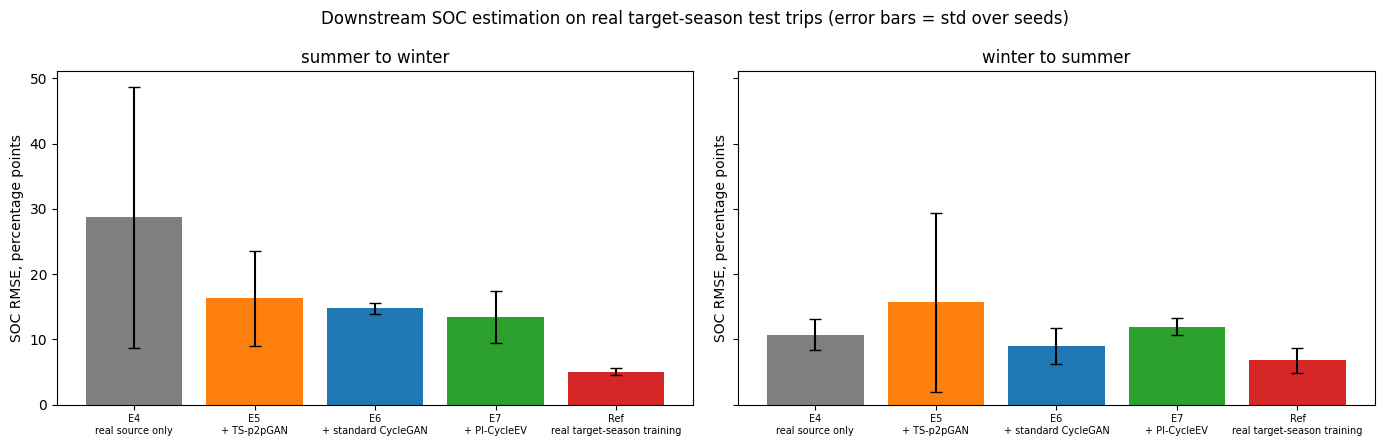

In [ ]:
# ==========================================
# 10.3 - SUMMARY TABLE AND FIGURE
# ==========================================
import matplotlib.pyplot as plt

agg = (soc_df.groupby(['direction', 'experiment'], sort=False)
       .agg(target_rmse=('target_rmse', 'mean'), target_rmse_std=('target_rmse', 'std'),
            target_mae=('target_mae', 'mean'), target_r2=('target_r2', 'mean'),
            source_rmse=('source_rmse', 'mean'), n_train=('n_train_windows', 'first')).round(3))
print("SOC estimation on REAL target-season test windows (RMSE and MAE in SOC percentage points; mean over seeds):")
display(agg)
agg.to_csv(f'{PROJECT_ROOT}/results/soc_experiment_summary_{tag}.csv')

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for a_, d in zip(ax, soc_df.direction.unique()):
    sub = agg.loc[d]
    a_.bar(range(len(sub)), sub.target_rmse, yerr=sub.target_rmse_std.fillna(0), capsize=4,
           color=['tab:gray', 'tab:orange', 'tab:blue', 'tab:green', 'tab:red'][:len(sub)])
    a_.set_xticks(range(len(sub))); a_.set_xticklabels([s.split(' ', 1)[0] + '\n' + s.split(' ', 1)[1] for s in sub.index], fontsize=7)
    a_.set_title(d.replace('_', ' ')); a_.set_ylabel('SOC RMSE, percentage points')
plt.suptitle('Downstream SOC estimation on real target-season test trips (error bars = std over seeds)')
plt.tight_layout()
plt.savefig(f'{PROJECT_ROOT}/results/figures/downstream_soc_rmse_{tag}.png', dpi=200)
plt.show()

In [ ]:
# ==========================================
# 10.4 - DIAGNOSTIC: do the synthetic training windows look like the real target-season test windows?
# ==========================================
show = ['soc', 'voltage', 'current', 'batt_temp']
def pool_stats(W):
    p = inverse_scale(W).reshape(-1, len(FEATURES))
    return {f: (round(float(p[:, FEATURES.index(f)].mean()), 1), round(float(p[:, FEATURES.index(f)].std()), 1)) for f in show}

print("mean, std (real units) of each estimator input / label in each pool of windows\n")
for d, synth in ALL_SYNTH.items():
    src, tgt = d.split('_to_')
    print(f"=== {d} ===")
    print(f"  {'real ' + tgt + ' TEST (what we are scored on)':46s}", pool_stats(data[tgt]['test']))
    print(f"  {'real ' + src + ' TRAIN (E4 trains on this)':46s}", pool_stats(data[src]['train']))
    for label, W in synth.items():
        print(f"  {'synthetic: ' + label:46s}", pool_stats(W))
    print()

mean, std (real units) of each estimator input / label in each pool of windows

=== summer_to_winter ===
  real winter TEST (what we are scored on)       {'soc': (59.7, 17.7), 'voltage': (370.1, 12.8), 'current': (-25.5, 41.4), 'batt_temp': (9.0, 1.9)}
  real summer TRAIN (E4 trains on this)          {'soc': (73.6, 8.4), 'voltage': (383.1, 5.9), 'current': (-15.8, 35.6), 'batt_temp': (22.3, 3.3)}
  synthetic: E5 + TS-p2pGAN                      {'soc': (73.4, 8.3), 'voltage': (382.9, 5.8), 'current': (-15.8, 35.6), 'batt_temp': (22.3, 3.3)}
  synthetic: E6 + standard CycleGAN              {'soc': (73.1, 3.4), 'voltage': (375.6, 9.9), 'current': (-31.9, 55.0), 'batt_temp': (4.4, 1.1)}
  synthetic: E7 + PI-CycleEV                     {'soc': (80.0, 1.9), 'voltage': (380.3, 5.8), 'current': (-23.1, 39.2), 'batt_temp': (5.2, 1.4)}

=== winter_to_summer ===
  real summer TEST (what we are scored on)       {'soc': (65.0, 12.8), 'voltage': (378.9, 8.0), 'current': (-18.1, 35.2), 'batt_temp': 

In [ ]:
# ==========================================
# 10.5 - CHECK: are the generated windows plausible in MAGNITUDE (not just consistent)?
# ==========================================
CAP_AH, DT_S = 60.0, 1.0
CUR_C = FEATURES.index('current')

def window_physics(W):
    p = inverse_scale(W)
    soc, cur = p[:, :, SOC_C], p[:, :, CUR_C]
    dsoc = soc[:, -1] - soc[:, 0]                                                      # SOC change over the window, % points
    implied = ((cur[:, 1:] + cur[:, :-1]) / 2).sum(axis=1) * DT_S * 100 / (CAP_AH * 3600)   # change implied by the current, % points
    return dict(mean_current_A=cur.mean(), mean_dSOC=dsoc.mean(), mean_abs_dSOC=np.abs(dsoc).mean(),
                mean_implied_dSOC=implied.mean(), mean_abs_implied=np.abs(implied).mean())

print("per 256-second window; the real rows show what is normal. Units: A and SOC percentage points\n")
for d, synth in ALL_SYNTH.items():
    src, tgt = d.split('_to_')
    print(f"=== {d} ===")
    pools = {f'real {tgt} TEST': data[tgt]['test'], f'real {src} TRAIN': data[src]['train'], **{f'synthetic: {k}': v for k, v in synth.items()}}
    for name, W in pools.items():
        r = window_physics(W)
        print(f"  {name:36s} current {r['mean_current_A']:8.1f} A | SOC change {r['mean_dSOC']:6.1f} (abs {r['mean_abs_dSOC']:5.1f}) | "
              f"implied by current {r['mean_implied_dSOC']:6.1f} (abs {r['mean_abs_implied']:5.1f})")
    print()

per 256-second window; the real rows show what is normal. Units: A and SOC percentage points

=== summer_to_winter ===
  real winter TEST                     current    -25.5 A | SOC change   -2.8 (abs   2.8) | implied by current   -3.0 (abs   3.0)
  real summer TRAIN                    current    -15.8 A | SOC change   -1.8 (abs   1.8) | implied by current   -1.9 (abs   1.9)
  synthetic: E5 + TS-p2pGAN            current    -15.8 A | SOC change   -2.1 (abs   2.5) | implied by current   -1.9 (abs   1.9)
  synthetic: E6 + standard CycleGAN    current    -31.9 A | SOC change    9.7 (abs   9.7) | implied by current   -3.8 (abs   3.8)
  synthetic: E7 + PI-CycleEV           current    -23.1 A | SOC change   -3.0 (abs   3.0) | implied by current   -2.7 (abs   2.7)

=== winter_to_summer ===
  real summer TEST                     current    -18.1 A | SOC change   -2.1 (abs   2.1) | implied by current   -2.1 (abs   2.2)
  real winter TRAIN                    current    -25.8 A | SOC change   -2

In [ ]:
# ==========================================
# 11.1 - ABLATION RUNS (each physics term removed in turn)
# ==========================================
ABLATIONS = {'abl_no_soc':   (0.0,     LAM_VA, LAM_RANGE),     # SOC-current term removed
             'abl_no_va':    (LAM_SOC, 0.0,    LAM_RANGE),     # velocity-acceleration term removed
             'abl_no_range': (LAM_SOC, LAM_VA, 0.0)}           # window-level plausibility / range term removed
abl_hist = {}
if RUN_ABLATIONS:
    for run, lams in ABLATIONS.items():
        abl_hist[run], _, _ = run_or_load(run, *lams)
else:
    print("RUN_ABLATIONS = False: ablation runs skipped.")

[abl_no_soc] found saved weights (full); loading them. Set RETRAIN_IN_FULL_MODE = True in cell 01.3 to retrain.
[abl_no_va] found saved weights (full); loading them. Set RETRAIN_IN_FULL_MODE = True in cell 01.3 to retrain.
[abl_no_range] found saved weights (full); loading them. Set RETRAIN_IN_FULL_MODE = True in cell 01.3 to retrain.


Ablation (averaged over both seasonal directions). Physics residuals: 0 = consistent. mean_abs_dSOC and mean_current_A should be close to the REAL row. cycle_rmse and wasserstein are in % of range.


,phys_soc_residual,phys_va_residual,mean_abs_dSOC,mean_current_A,cycle_rmse_pct,wasserstein_pct
model,,,,,,
E2: all physics off,13.547,8.691,7.202,-22.240,15.956,7.819
no SOC-current,0.719,2.890,0.396,-21.099,17.353,7.458
no velocity-accel,0.043,24.193,0.089,-4.184,21.001,10.939
no plausibility range,0.007,3.099,0.943,-8.327,16.142,9.032
E3: full PI-CycleEV,0.104,2.308,1.508,-13.896,17.427,10.488
REAL test windows,0.025,0.152,2.432,-21.820,NaN,NaN


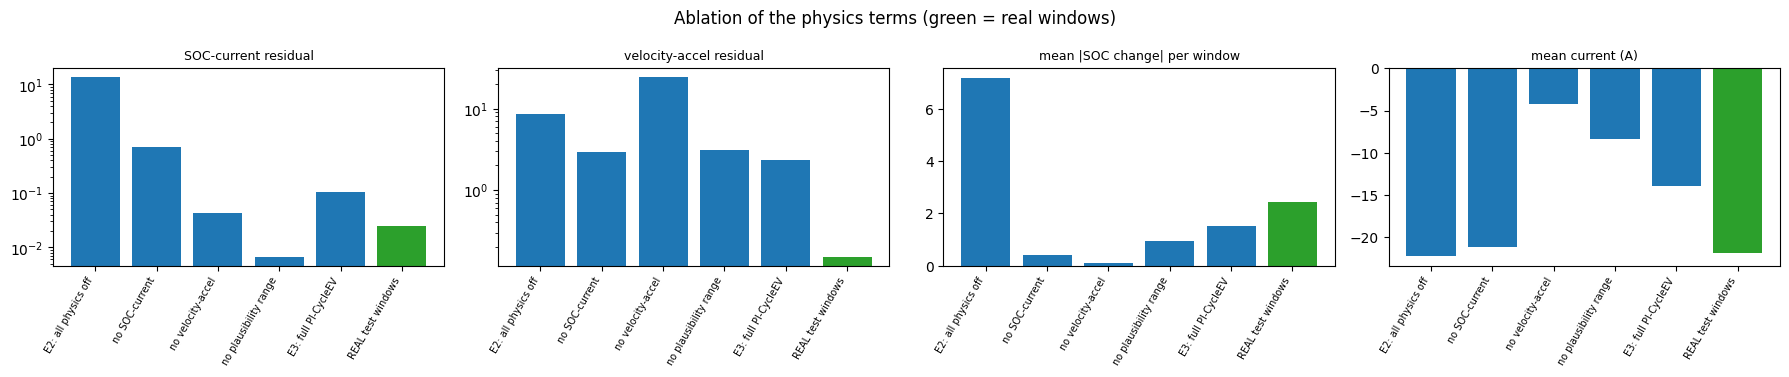

In [ ]:
# ==========================================
# 11.2 - ABLATION RESULTS (test windows of both seasons)
# ==========================================
ABL_RUNS = {'E2: all physics off':    'cyclegan_nophys',
            'no SOC-current':         'abl_no_soc',
            'no velocity-accel':      'abl_no_va',
            'no plausibility range':  'abl_no_range',
            'E3: full PI-CycleEV':    'picycleev'}
SOC_C, CUR_C = FEATURES.index('soc'), FEATURES.index('current')

def magnitude_stats(W):
    p = inverse_scale(W)
    return float(np.abs(p[:, -1, SOC_C] - p[:, 0, SOC_C]).mean()), float(p[:, :, CUR_C].mean())

rows = []
for label, run in ABL_RUNS.items():
    if not have_run(run):
        print(f"skipping '{label}': no saved weights for {run}"); continue
    G_AB, G_BA = load_generators(run)
    fw, fs = generate(G_AB, src_s), generate(G_BA, src_w)                     # generated winter / summer test windows
    cyc_s, cyc_w = generate(G_BA, fw), generate(G_AB, fs)
    ps_w, pv_w = physics_residuals(fw); ps_s, pv_s = physics_residuals(fs)
    w1 = [wasserstein_distance(flat_phys(src_w)[:, c], flat_phys(fw)[:, c]) / RANGE[c] * 100 for c in OUT_IDX]
    w2 = [wasserstein_distance(flat_phys(src_s)[:, c], flat_phys(fs)[:, c]) / RANGE[c] * 100 for c in OUT_IDX]
    d1, c1 = magnitude_stats(fw); d2, c2 = magnitude_stats(fs)
    rows.append(dict(model=label, phys_soc_residual=(ps_w + ps_s) / 2, phys_va_residual=(pv_w + pv_s) / 2,
                     mean_abs_dSOC=(d1 + d2) / 2, mean_current_A=(c1 + c2) / 2,
                     cycle_rmse_pct=(rmse_pct(src_s, cyc_s, OUT_IDX) + rmse_pct(src_w, cyc_w, OUT_IDX)) / 2,
                     wasserstein_pct=float(np.mean(w1 + w2))))

# reference: real test windows
rs_, rv_ = physics_residuals(src_s); rs2, rv2 = physics_residuals(src_w)
ds_, cs_ = magnitude_stats(src_s); dw_, cw_ = magnitude_stats(src_w)
rows.append(dict(model='REAL test windows', phys_soc_residual=(rs_ + rs2) / 2, phys_va_residual=(rv_ + rv2) / 2,
                 mean_abs_dSOC=(ds_ + dw_) / 2, mean_current_A=(cs_ + cw_) / 2, cycle_rmse_pct=np.nan, wasserstein_pct=np.nan))

abl_df = pd.DataFrame(rows).set_index('model')
print("Ablation (averaged over both seasonal directions). Physics residuals: 0 = consistent. "
      "mean_abs_dSOC and mean_current_A should be close to the REAL row. cycle_rmse and wasserstein are in % of range.")
display(abl_df.round(3))
abl_df.to_csv(f'{PROJECT_ROOT}/results/ablation_{tag}.csv')

fig, ax = plt.subplots(1, 4, figsize=(18, 3.8))
for a_, col, title, log in zip(ax, ['phys_soc_residual', 'phys_va_residual', 'mean_abs_dSOC', 'mean_current_A'],
                               ['SOC-current residual', 'velocity-accel residual', 'mean |SOC change| per window', 'mean current (A)'],
                               [True, True, False, False]):
    d = abl_df[col]
    a_.bar(range(len(d)), d.values, color=['tab:green' if i == 'REAL test windows' else 'tab:blue' for i in d.index])
    a_.set_xticks(range(len(d))); a_.set_xticklabels(d.index, rotation=60, ha='right', fontsize=7); a_.set_title(title, fontsize=9)
    if log: a_.set_yscale('log')
plt.suptitle('Ablation of the physics terms (green = real windows)')
plt.tight_layout()
plt.savefig(f'{PROJECT_ROOT}/results/figures/ablation_{tag}.png', dpi=200)
plt.show()

In [ ]:
# ==========================================
# 12.1 - FINAL TABLES (re-read from the files the sections above saved, so every number is traceable)
# ==========================================
out_name = 'metrics_test.csv' if TEST_MODE else 'metrics.csv'
Mf = pd.read_csv(f'{PROJECT_ROOT}/results/{out_name}')
tg = Mf[Mf.channel.isin(OUT_NAMES)]
keys = ['experiment', 'direction']
final = pd.DataFrame({
    'wasserstein_%range':   tg[tg.metric == 'wasserstein_%range'].groupby(keys).value.mean(),
    'corr_diff':            Mf[Mf.metric == 'corr_outputs_mean_abs_diff'].groupby(keys).value.mean(),
    'diversity_soc':        tg[(tg.metric == 'window_mean_std_ratio') & (tg.channel == 'soc')].groupby(keys).value.mean(),
    'phys_soc_residual':    Mf[Mf.metric == 'phys_soc_residual'].groupby(keys).value.mean(),
    'phys_va_residual':     Mf[Mf.metric == 'phys_va_residual'].groupby(keys).value.mean()})
print("Final comparison on held-out test trips (target signals; see Section 09 for the definitions):")
display(final.round(3))
final.to_csv(f'{PROJECT_ROOT}/results/final_summary_{tag}.csv')

for name, title in [(f'soc_experiment_summary_{tag}.csv', "Downstream SOC estimation (Section 10), SOC percentage points:"),
                    (f'ablation_{tag}.csv', "Ablation (Section 11):")]:
    p = f'{PROJECT_ROOT}/results/{name}'
    print("\n" + title)
    display(pd.read_csv(p)) if os.path.exists(p) else print(f"  (missing {name})")

In [ ]:
# ==========================================
# 12.2 - REPRODUCIBILITY SUMMARY
# ==========================================
summary_json = {
    'mode': tag, 'seed': SEED, 'split_seed': SPLIT_SEED, 'gpu': GPU_NAME,
    'versions': {'python': platform.python_version(), 'tensorflow': tf.__version__, 'numpy': np.__version__,
                 'pandas': pd.__version__, 'scikit-learn': sklearn.__version__, 'scipy': scipy.__version__, 'tslearn': tslearn.__version__},
    'data': {'window': WINDOW_SIZE, 'stride': STRIDE, 'downsample_factor': DOWNSAMPLE, 'smoothing_window': SMOOTH_WINDOW,
             'trips_per_split': {s: {k: len(v) for k, v in d.items()} for s, d in split.items()},
             'windows_per_split': {s: {k: int(len(v)) for k, v in d.items()} for s, d in data.items()}},
    'training': {'batch_size': BATCH_SIZE, 'baseline_epochs': P2P_EPOCHS, 'cyclegan_epochs': CYCLE_EPOCHS,
                 'baseline_lambda_L1': LAMBDA_L1, 'baseline_lr': P2P_LR,
                 'cyclegan_lambda_cycle': LAMBDA_CYCLE, 'cyclegan_lambda_identity': LAMBDA_ID, 'cyclegan_lr': LR,
                 'physics_weights': {'soc_current': LAM_SOC, 'velocity_accel': LAM_VA, 'range': LAM_RANGE},
                 'ablations_run': bool(RUN_ABLATIONS), 'retrained_this_run': bool(RETRAIN),
                 'resumed_runs': {'picycleev': 'continued from the epoch-70 checkpoint', 'abl_no_range': 'continued from the epoch-20 checkpoint',
                                  'note': 'generators restored from the checkpoint; discriminators and optimisers re-initialised'}},
    'trainable_parameters': {'baseline_generator': build_p2p_generator().count_params(),
                             'baseline_discriminator': build_p2p_discriminator().count_params(),
                             'cyclegan_generator_each': build_generator('g').count_params(),
                             'cyclegan_discriminator_each': build_discriminator('d').count_params(),
                             'soc_estimator': build_estimator().count_params()},
    'notebook_runtime_minutes': round((time.time() - NOTEBOOK_START) / 60, 1),
}
with open(f'{PROJECT_ROOT}/results/reproducibility_summary_{tag}.json', 'w') as f:
    json.dump(summary_json, f, indent=2)
print(json.dumps(summary_json, indent=2))

In [ ]:
# ==========================================
# 12.3 - EVERYTHING THIS RUN SAVED
# ==========================================
for sub in ['results', 'results/figures', 'models']:
    folder = f'{PROJECT_ROOT}/{sub}'
    files = sorted(f for f in os.listdir(folder) if os.path.isfile(f'{folder}/{f}') and f.endswith(f'_{tag}.' + f.split('.')[-1]))
    print(f"\n{sub}/  ({len(files)} files from this mode)")
    for f in files:
        print(f"  {f:62s} {os.path.getsize(f'{folder}/{f}') / 1e6:8.2f} MB")
print("\nDone.")